In [1]:
%pip install scikit-learn 
%pip install torch torchvision torchaudio
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Introdução ao Aprendizado de Máquina -- MC886
# Trabalho 2 - Seleção de Modelos e Regularização

**Professor:** Marcelo da Silva Reis  
**PED:** Heigon Soldera

In [2]:
# Please, enter your name and RA number in the lines below:
print("Ana Carolina de Almeida Cardoso", "|", "246914")
print("Francisco Vinicius Guedes", "|", "260440")
print("Pedro Damasceno Vasconcellos", "|", "260640")  # You may remove this line if you are only 2 students in the group

Ana Carolina de Almeida Cardoso | 246914
Francisco Vinicius Guedes | 260440
Pedro Damasceno Vasconcellos | 260640


---

## Objetivo

Este trabalho investiga os efeitos do sobreajuste em diferentes regimes de disponibilidade de dados e condições de teste.
O objetivo é compreender os diferentes resultados da regularização quando a disponibilidade de dados muda e como eles afetam a generalização em **três** distribuições distintas: a utilizada no treinamento, a de imagens sem corrupção e a de uma corrupção que o modelo nunca viu.

### Orientações

> Leia estas orientações com atenção.

1. As questões podem ser respondidas em inglês ou em português.

2. Use a visualização de dados como principal ferramenta para compreender o problema. Examine os dados de treinamento, as entradas corrompidas e o comportamento do modelo. Quando uma suposição for incerta, verifique-a empiricamente por meio de gráficos.

3. O código fornecido serve apenas como referência. São permitidas modificações, incluindo alterações nas funções e a introdução de novos componentes. São exigidas clareza e organização do código.

4. O uso de ferramentas de IA generativa (por exemplo, ChatGPT, GitHub Copilot, DeepSeek, LLaMA) é permitido estritamente para auxiliar na implementação. O uso de IA para interpretar, analisar ou discutir resultados experimentais é desencorajado. As entregas devem incluir:
   - Uma declaração dos modelos utilizados.
   - Os prompts que geraram qualquer código incorporado ao trabalho.

5. Não hesite em entrar em contato com o PED/PAD pelo Discord.

### Sobre o conjunto de dados

Este trabalho utiliza o conjunto de dados [MNIST](https://web.archive.org/web/20240213122836/http://yann.lecun.com/exdb/mnist/), uma referência padrão para classificação de imagens. Ele consiste em imagens de dígitos manuscritos (0–9), com 28×28 pixels em tons de cinza, em que cada pixel representa um valor de intensidade no intervalo [0, 255].

O MNIST é útil aqui porque é simples o suficiente para que um modelo linear tenha bom desempenho. Isso significa que os pesos aprendidos podem ser interpretados diretamente como imagens, nas quais cada peso corresponde à influência de um pixel.

Para estudar a robustez e a mudança de distribuição, as imagens foram corrompidas com uma das corrupções do [MNIST-C](https://github.com/google-research/mnist-c) (Mu & Gilmer, 2019). Descobrir qual é essa corrupção faz parte da Parte 1.

O conjunto de treinamento é composto inteiramente por imagens corrompidas. O conjunto de teste contém **três versões** das mesmas 10.000 imagens de teste:
- `test_corrupted`: imagens de teste corrompidas (mesma corrupção do treinamento).
- `test_clean`: imagens de teste originais do MNIST, sem corrupção.
- `test_impulse`: imagens de teste com uma corrupção **diferente**, o ruído impulsivo (sal e pimenta), nunca visto durante o treinamento.

O desempenho em `test_corrupted` mede o quanto o modelo aprendeu a tarefa de treinamento.
O desempenho em `test_clean` mede o quanto o modelo aprendeu a reconhecer dígitos.
O desempenho em `test_impulse` mede se a robustez adquirida durante o treinamento se transfere para uma corrupção à qual o modelo nunca foi exposto.

Sua tarefa é treinar três modelos diferentes, cada um com uma quantidade distinta de amostras disponíveis:
- Dados completos (Full-data): 60.000 amostras.
- Dados parciais (Partial-data): 10.000 amostras.
- Dados escassos (Scarce-data): 1.000 amostras.

Encontre a melhor combinação de hiperparâmetros para cada um deles.

In [3]:
from typing import Any, Callable

from numpy.typing import NDArray
import numpy as np
import pandas as pd
import random

import torch
import torch.nn as nn
from torch import optim

import matplotlib.pyplot as plt
import seaborn as sns

# Set random seeds for reproducibility.
# Do not tune this number
# Re-run the notebook from the beginning before submitting.
seed = 42
torch.random.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

In [4]:
# The dataset is available in the classroom assignment.
# Ensure you have downloaded it and placed it alongside this notebook.

# DO NOT change this cell

def subsample_dataset(
    X: NDArray[Any], y: NDArray[Any], n: int
) -> tuple[NDArray[Any], NDArray[Any]]:
    n_samples = len(y)

    idxs = np.random.choice(
        n_samples, size=n, replace=False
    )

    return X[idxs], y[idxs]

DATA_DIR = "data_2s2026"

X_full = np.load(f"{DATA_DIR}/train/train_images.npy")
y_full = np.load(f"{DATA_DIR}/train/train_labels.npy")

X_partial, y_partial = subsample_dataset(X_full, y_full, 10_000)
X_scarce, y_scarce = subsample_dataset(X_full, y_full, 1_000)

print(f"Full-data set: {X_full.shape[0]} samples")
print(f"Partial-data set: {X_partial.shape[0]} samples")
print(f"Scarce-data set: {X_scarce.shape[0]} samples")

Full-data set: 60000 samples
Partial-data set: 10000 samples
Scarce-data set: 1000 samples


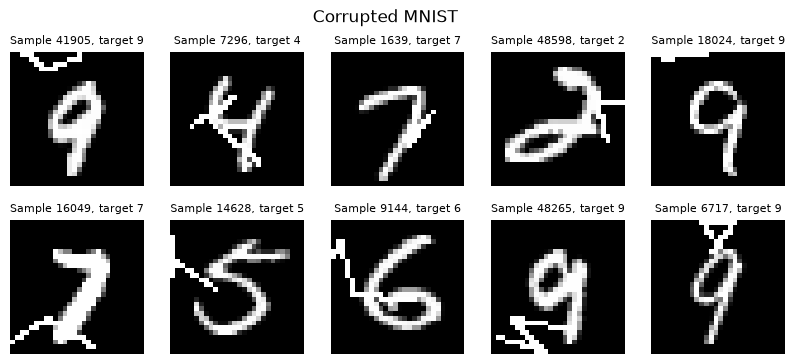

In [5]:
n_cols = 5
n_rows = 2

fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(2*n_cols, 2*n_rows))

fig.suptitle("Corrupted MNIST")

for i in range(n_rows):
    for j in range(n_cols):
        ax = axs[i, j]
        idx = random.randint(0, len(X_full)-1)

        ax.set_title(f"Sample {idx}, target {y_full[idx]}", fontsize=8)
        ax.imshow(X_full[idx], cmap='grey')
        ax.set_axis_off()

---

## Parte 1. Análise e pré-processamento dos dados

### 1.1 Explorando a corrupção

**(1,0 ponto)**

Antes de realizar qualquer modelagem, compreenda o que a corrupção realmente faz com os dados.

A corrupção é um ruído aleatório por pixel ou uma perturbação estruturada?
Explore o conjunto de dados de **treinamento** e compreenda a distribuição e os efeitos do ruído introduzido. Algumas ferramentas úteis são as imagens médias por classe, as estatísticas por pixel (por exemplo, a frequência com que cada pixel está saturado em 255) e a visualização de várias amostras individuais lado a lado.

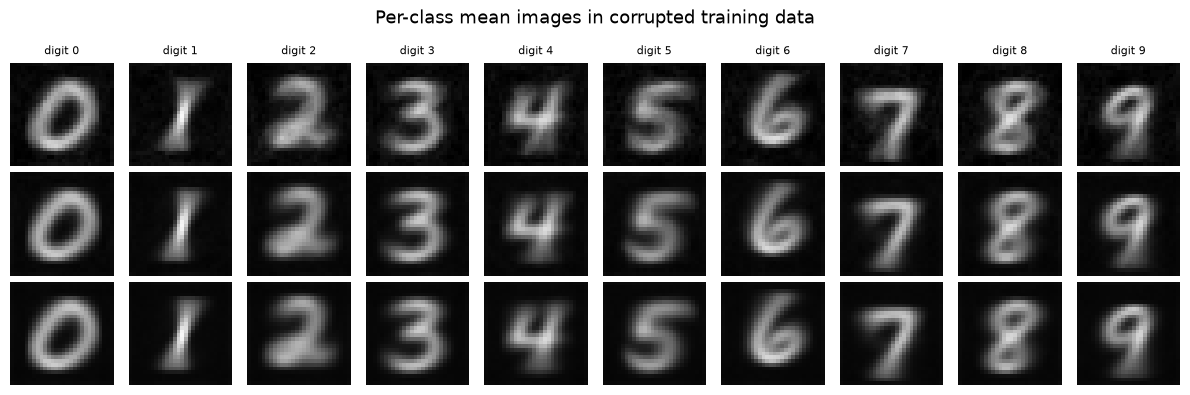

In [6]:
data_regimes = {
    "Scarce": (X_scarce, y_scarce),
    "Partial": (X_partial, y_partial),
    "Full": (X_full, y_full),
}

fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))
for digit in range(10):
    axs[0, digit].set_title(f"digit {digit}", fontsize=8)

for i, name in enumerate(data_regimes):
    X, y = data_regimes[name]


    for digit in range(10):
        mask = (y == digit)
        mean_img = X[mask].mean(axis=0)
        axs[i, digit].imshow(mean_img, cmap="gray", vmin=0, vmax=255)
        axs[i, digit].axis("off")

    axs[i, 0].set_ylabel(f"{name}-data regime", fontsize=9)

plt.suptitle("Per-class mean images in corrupted training data", fontsize=13)
plt.tight_layout()
plt.show()

#### Amostras corrompidas por classe de dígito

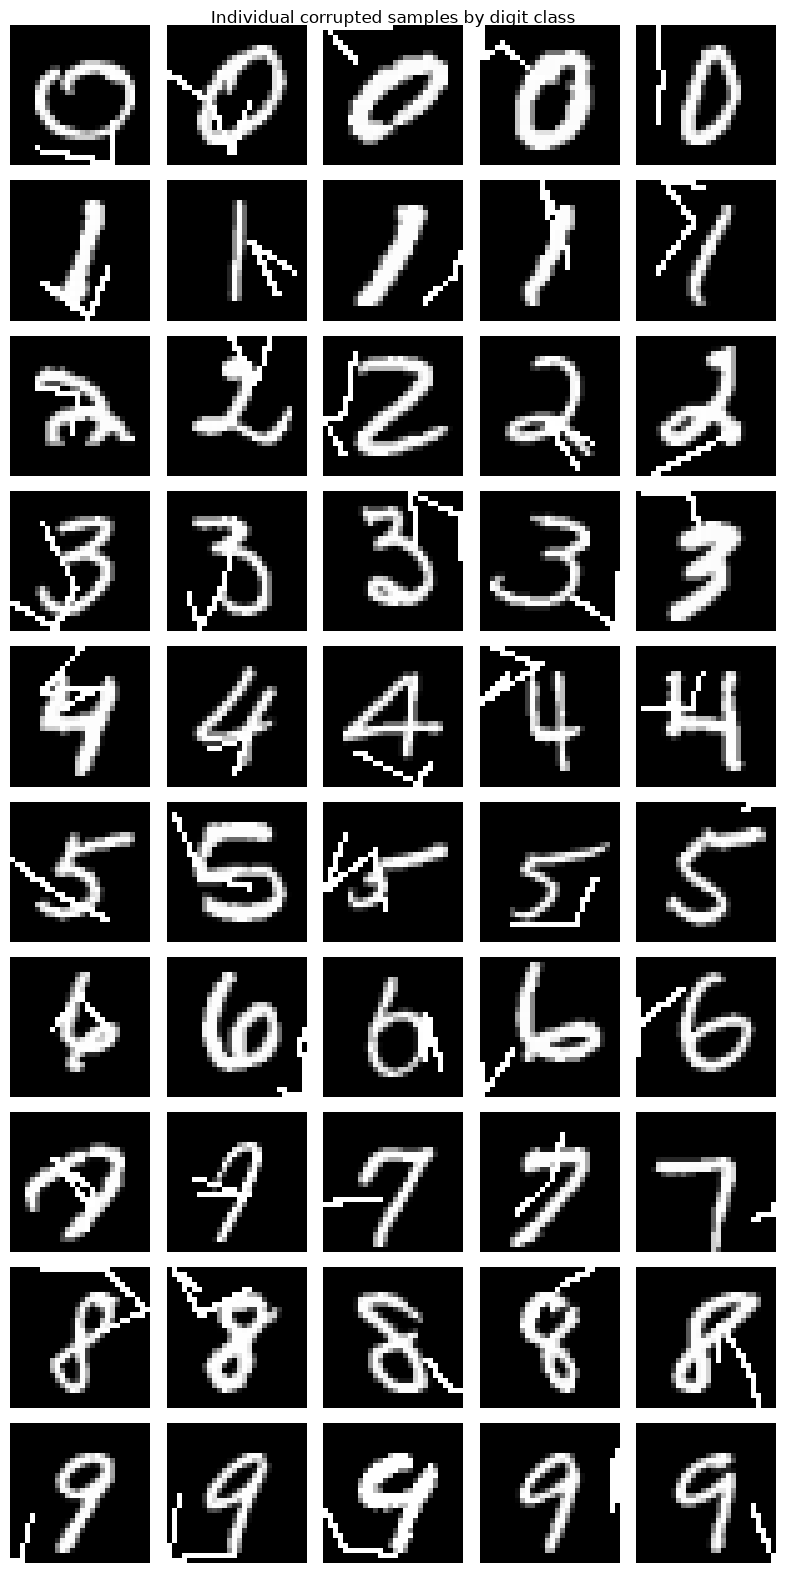

In [7]:
# ============================================================
# Check random corrupted samples by digit class
# ============================================================

fig, axs = plt.subplots(10, 5, figsize=(8, 16))

for digit in range(10):

    idx = np.where(y_full == digit)[0]
    chosen = np.random.choice(idx, size=5, replace=False)

    for j, sample_idx in enumerate(chosen):

        axs[digit, j].imshow(
            X_full[sample_idx],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[digit, j].axis("off")

        if j == 0:
            axs[digit, j].set_ylabel(
                f"Digit {digit}",
                fontsize=10
            )

plt.suptitle("Individual corrupted samples by digit class")
plt.tight_layout()
plt.show()

#### Mapas de média e variância por pixel

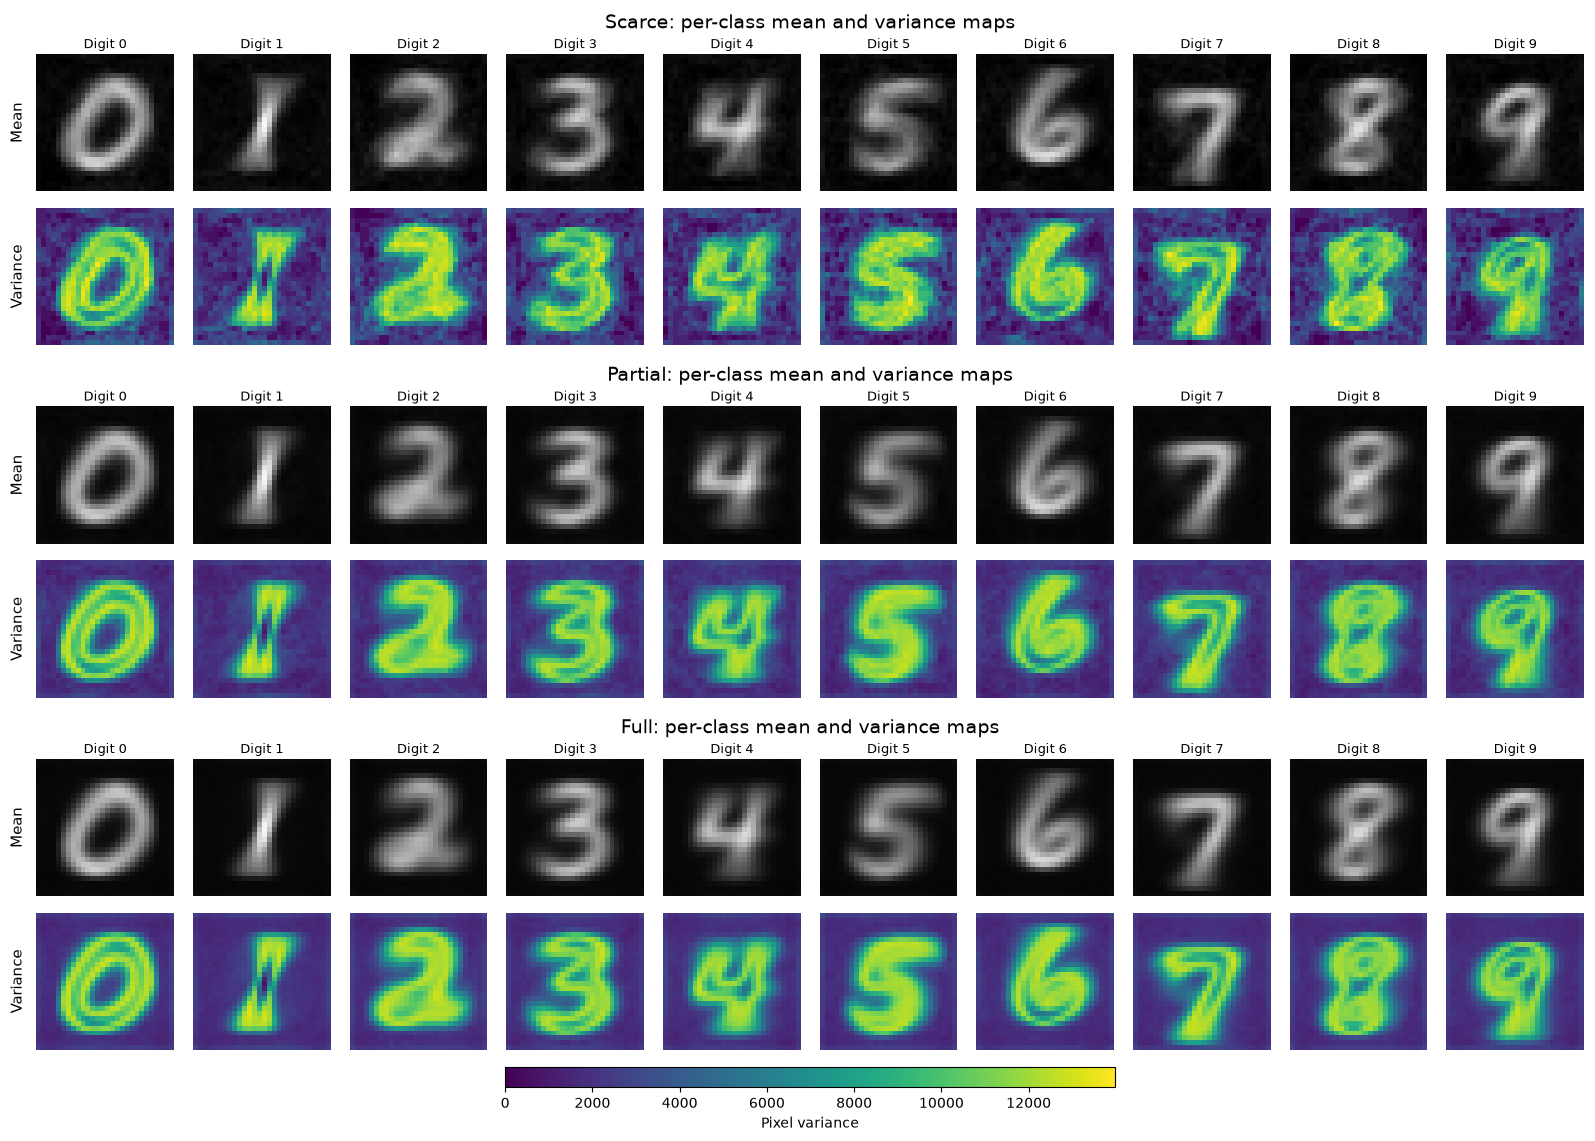

In [8]:
import numpy as np
import matplotlib.pyplot as plt

regimes = {
    "Scarce": (X_scarce, y_scarce),
    "Partial": (X_partial, y_partial),
    "Full": (X_full, y_full)
}

# ============================================================
# Compute mean and variance maps beforehand
# ============================================================

mean_maps = {}
var_maps = {}

for regime_name, (X, y) in regimes.items():

    mean_maps[regime_name] = []
    var_maps[regime_name] = []

    for digit in range(10):

        X_digit = X[y == digit]

        mean_maps[regime_name].append(
            X_digit.mean(axis=0)
        )

        var_maps[regime_name].append(
            X_digit.var(axis=0)
        )


# ============================================================
# Common variance scale across ALL regimes and digits
# ============================================================

var_vmax = max(
    var_img.max()
    for regime_name in regimes
    for var_img in var_maps[regime_name]
)


# ============================================================
# Figure layout
#
# Rows:
# 0 -> Scarce title
# 1 -> Scarce mean
# 2 -> Scarce variance
#
# 3 -> Partial title
# 4 -> Partial mean
# 5 -> Partial variance
#
# 6 -> Full title
# 7 -> Full mean
# 8 -> Full variance
#
# 9 -> colorbar
# ============================================================

fig = plt.figure(figsize=(20, 14))

gs = fig.add_gridspec(
    nrows=10,
    ncols=10,
    height_ratios=[
        0.20, 1, 1,
        0.20, 1, 1,
        0.20, 1, 1,
        0.15
    ],
    hspace=0.18,
    wspace=0.12
)


regime_rows = {
    "Scarce": (0, 1, 2),
    "Partial": (3, 4, 5),
    "Full": (6, 7, 8)
}

last_im = None


# ============================================================
# Plot each regime
# ============================================================

for regime_name in regimes:

    title_row, mean_row, var_row = regime_rows[regime_name]

    # --------------------------------------------------------
    # Regime title
    # --------------------------------------------------------

    title_ax = fig.add_subplot(gs[title_row, :])

    title_ax.text(
        0.5,
        0.5,
        f"{regime_name}: per-class mean and variance maps",
        ha="center",
        va="center",
        fontsize=14
    )

    title_ax.axis("off")


    # --------------------------------------------------------
    # Mean and variance maps
    # --------------------------------------------------------

    for digit in range(10):

        # --------------------
        # Mean
        # --------------------

        ax_mean = fig.add_subplot(gs[mean_row, digit])

        ax_mean.imshow(
            mean_maps[regime_name][digit],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        ax_mean.set_title(
            f"Digit {digit}",
            fontsize=9,
            pad=4
        )

        ax_mean.set_xticks([])
        ax_mean.set_yticks([])

        for spine in ax_mean.spines.values():
            spine.set_visible(False)


        # --------------------
        # Variance
        # --------------------

        ax_var = fig.add_subplot(gs[var_row, digit])

        last_im = ax_var.imshow(
            var_maps[regime_name][digit],
            cmap="viridis",
            vmin=0,
            vmax=var_vmax
        )

        ax_var.set_xticks([])
        ax_var.set_yticks([])

        for spine in ax_var.spines.values():
            spine.set_visible(False)


        # Row labels only on the first digit
        if digit == 0:

            ax_mean.set_ylabel(
                "Mean",
                fontsize=11,
                rotation=90,
                labelpad=8
            )

            ax_var.set_ylabel(
                "Variance",
                fontsize=11,
                rotation=90,
                labelpad=8
            )


# ============================================================
# Dedicated colorbar axis
# ============================================================

cax = fig.add_subplot(gs[9, 3:7])

cbar = fig.colorbar(
    last_im,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(
    "Pixel variance",
    fontsize=10
)

plt.show()

#### Distribuição das intensidades dos pixels

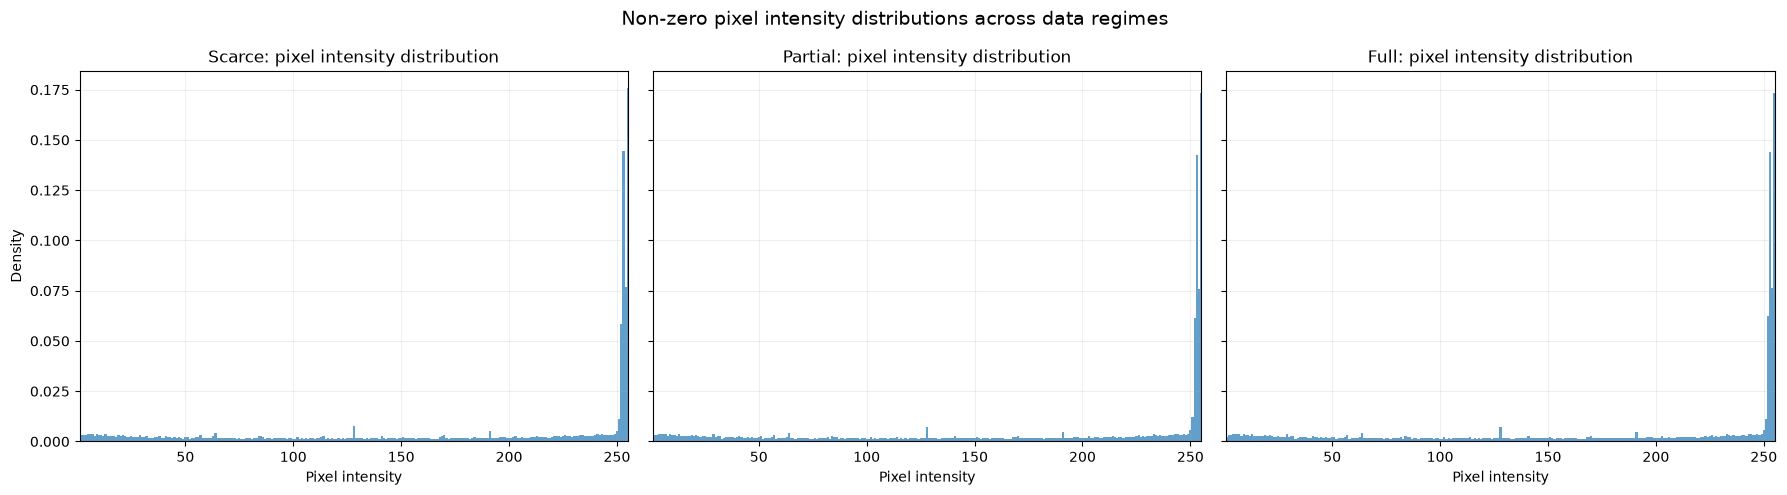

In [9]:
# ============================================================
# Non-zero pixel intensity distributions by data regime
# ============================================================

regimes = {
    "Scarce": X_scarce,
    "Partial": X_partial,
    "Full": X_full
}

fig, axs = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

bins = np.arange(1, 257) - 0.5

for ax, (regime_name, X) in zip(axs, regimes.items()):

    pixel_values = X.ravel()

    # Remove background pixels
    nonzero_pixels = pixel_values[pixel_values > 0]

    ax.hist(
        nonzero_pixels,
        bins=bins,
        density=True,
        histtype="stepfilled",
        alpha=0.7
    )

    ax.set_title(
        f"{regime_name}: pixel intensity distribution",
        fontsize=12
    )

    ax.set_xlabel("Pixel intensity")
    ax.set_xlim(1, 255)

    ax.grid(alpha=0.2)

# Shared y-axis label
axs[0].set_ylabel("Density")

fig.suptitle(
    "Non-zero pixel intensity distributions across data regimes",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Mapas de frequência de saturação por pixel nos diferentes regimes de dados

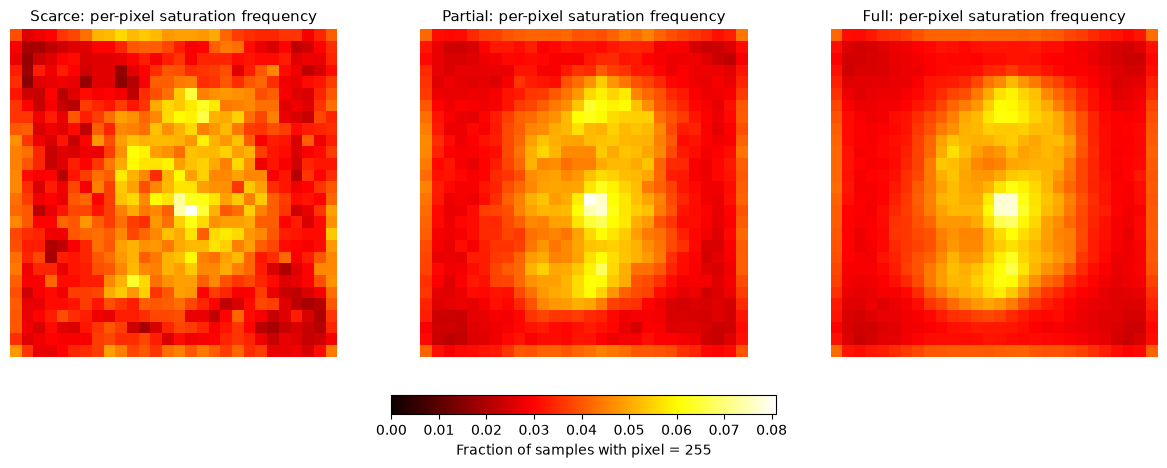

In [10]:
# ============================================================
# Per-pixel saturation frequency maps across data regimes
# ============================================================

regimes = {
    "Scarce": X_scarce,
    "Partial": X_partial,
    "Full": X_full
}

fig, axs = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

# Compute all maps first so they share the same scale
sat_maps = {
    name: (X == 255).mean(axis=0)
    for name, X in regimes.items()
}

sat_vmax = max(
    sat_map.max()
    for sat_map in sat_maps.values()
)

for ax, (name, sat_map) in zip(axs, sat_maps.items()):

    im = ax.imshow(
        sat_map,
        cmap="hot",
        vmin=0,
        vmax=sat_vmax
    )

    ax.set_title(
        f"{name}: per-pixel saturation frequency",
        fontsize=11
    )

    ax.axis("off")

# Shared colorbar
cbar = fig.colorbar(
    im,
    ax=axs,
    orientation="horizontal",
    fraction=0.05,
    pad=0.10
)

cbar.set_label("Fraction of samples with pixel = 255")

plt.show()

#### Número de pixels saturados por imagem

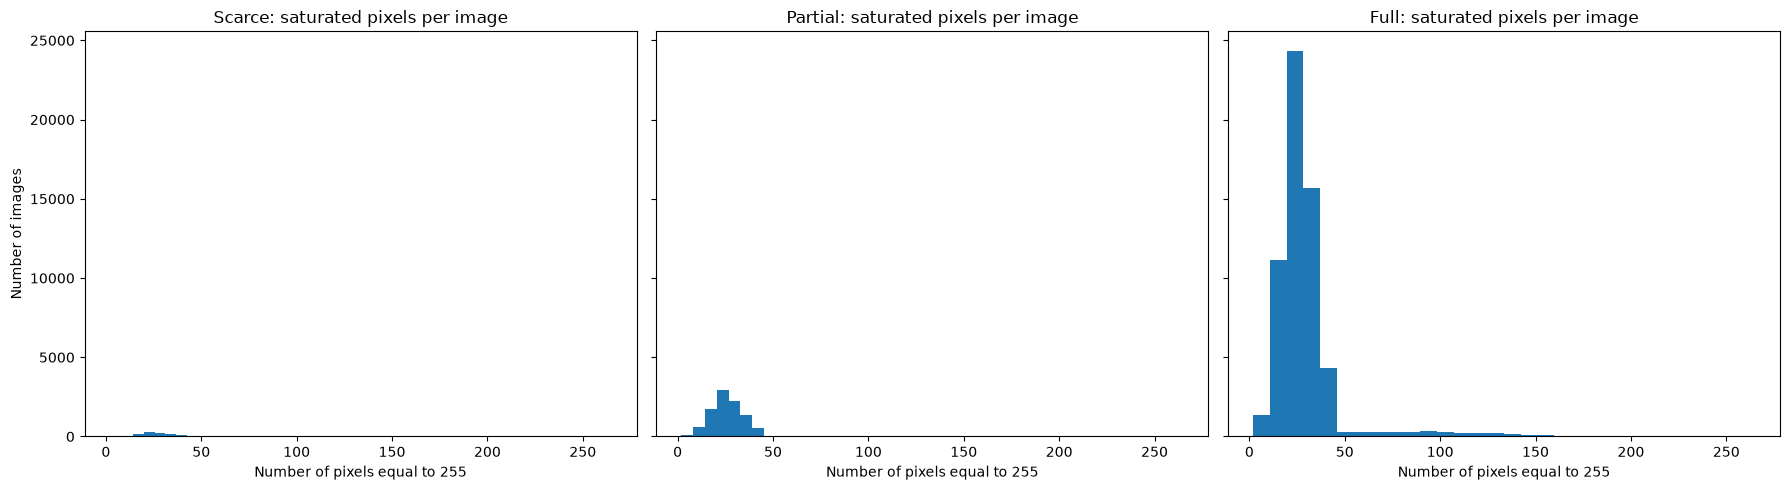

In [11]:
# ============================================================
# Number of saturated pixels per image across data regimes
# ============================================================

regimes = {
    "Scarce": X_scarce,
    "Partial": X_partial,
    "Full": X_full
}

fig, axs = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for ax, (name, X) in zip(axs, regimes.items()):

    n_saturated = (X == 255).sum(axis=(1, 2))

    ax.hist(
        n_saturated,
        bins=30
    )

    ax.set_title(
        f"{name}: saturated pixels per image"
    )

    ax.set_xlabel(
        "Number of pixels equal to 255"
    )

axs[0].set_ylabel("Number of images")

plt.tight_layout()
plt.show()

#### Fração de pixels com valores extremos por imagem

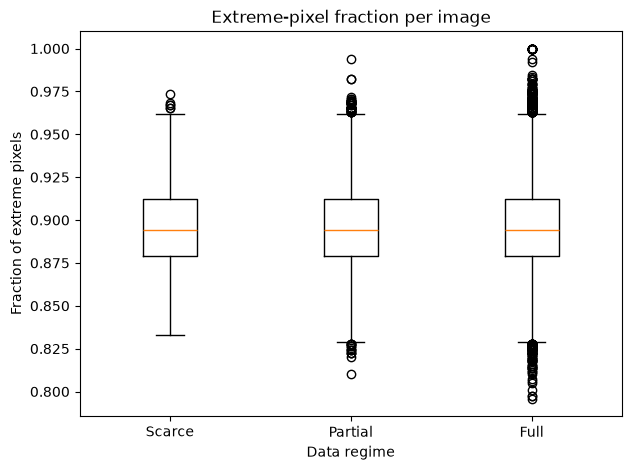

In [12]:
# ============================================================
# Extreme-pixel fraction per image
# ============================================================

regimes = {
    "Scarce": X_scarce,
    "Partial": X_partial,
    "Full": X_full
}

extreme_fraction_data = []

for name, X in regimes.items():

    # Convert to NumPy if X is a PyTorch tensor
    if torch.is_tensor(X):
        X_np = X.detach().cpu().numpy()
    else:
        X_np = np.asarray(X)

    # Flatten each image: (N, ...) -> (N, number_of_pixels)
    X_flat = X_np.reshape(len(X_np), -1)

    # Fraction of pixels close to either extreme, per image
    extreme_fraction = (
        (X_flat <= 10) | (X_flat >= 245)
    ).mean(axis=1)

    extreme_fraction_data.append(extreme_fraction)


plt.figure(figsize=(7, 5))

plt.boxplot(
    extreme_fraction_data,
    tick_labels=list(regimes.keys())
)

plt.title("Extreme-pixel fraction per image")
plt.xlabel("Data regime")
plt.ylabel("Fraction of extreme pixels")

plt.show()

#### Média e variância por imagem

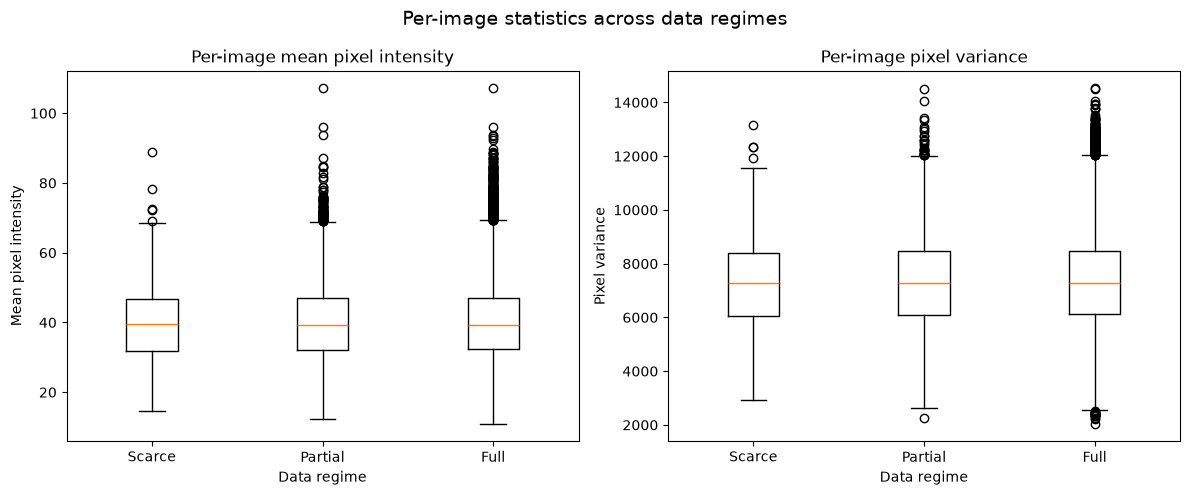

In [13]:
# ============================================================
# Per-image mean and variance across data regimes
# ============================================================

regimes = {
    "Scarce": X_scarce,
    "Partial": X_partial,
    "Full": X_full
}

image_mean_data = []
image_variance_data = []

for name, X in regimes.items():

    # Convert to NumPy if needed
    if torch.is_tensor(X):
        X_np = X.detach().cpu().numpy()
    else:
        X_np = np.asarray(X)

    # Flatten each image
    X_flat = X_np.reshape(len(X_np), -1)

    # One mean and one variance value per image
    image_mean = X_flat.mean(axis=1)
    image_variance = X_flat.var(axis=1)

    image_mean_data.append(image_mean)
    image_variance_data.append(image_variance)


# ============================================================
# Plot side by side
# ============================================================

fig, axs = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

labels = list(regimes.keys())


# ------------------------------------------------------------
# Per-image mean
# ------------------------------------------------------------

axs[0].boxplot(
    image_mean_data,
    tick_labels=labels
)

axs[0].set_title("Per-image mean pixel intensity")
axs[0].set_xlabel("Data regime")
axs[0].set_ylabel("Mean pixel intensity")


# ------------------------------------------------------------
# Per-image variance
# ------------------------------------------------------------

axs[1].boxplot(
    image_variance_data,
    tick_labels=labels
)

axs[1].set_title("Per-image pixel variance")
axs[1].set_xlabel("Data regime")
axs[1].set_ylabel("Pixel variance")


fig.suptitle(
    "Per-image statistics across data regimes",
    fontsize=14
)

plt.tight_layout()
plt.show()

> **Questão 1.1**
>
> (a) Descreva a corrupção. Ela é aleatória e específica de cada amostra ou é sistemática e compartilhada entre as imagens? Ela varia entre as classes de dígitos?
>
> (b) Por que a corrupção se transforma em um fundo tênue e quase uniforme nas imagens médias por classe? O que isso revela sobre o uso de imagens médias para diagnosticar uma corrupção?
>
> (c) A corrupção é composta por traços, e os dígitos também são compostos por traços. Quais dígitos você espera que sejam mais facilmente confundidos com a corrupção ou por causa dela?
>
> (d) Há regimes de dados nos quais a corrupção pode afetar o modelo mais do que em outros?
> Formule hipóteses sobre como esses diferentes regimes afetarão um modelo treinado com eles.

**(a)** A corrupção parece ser aleatória no nível das amostras, mas estruturada dentro de cada amostra. Não se trata de ruído independente por pixel: os artefatos adicionados formam traços coerentes, semelhantes a linhas. Entretanto, suas posições e orientações variam entre as imagens. Como a corrupção não está espacialmente alinhada de uma amostra para outra, ela não produz um padrão fixo forte nas médias por classe.

Não há evidências fortes de que o mecanismo de corrupção em si dependa da classe. O mesmo tipo de traço adicionado pode ser observado em todas as classes de dígitos. Os mapas de média e variância por classe também são muito semelhantes nos três regimes de dados. As diferenças entre as classes se devem principalmente à geometria dos próprios dígitos, e não a um processo de corrupção claramente diferente.

A distribuição das intensidades dos pixels, as frações de pixels com valores extremos, as médias por imagem e as variâncias por imagem também são muito semelhantes entre os regimes de dados escassos, parciais e completos. Isso reforça a ideia de que os conjuntos de dados são amostrados essencialmente do mesmo processo de geração de dados corrompidos.

---

**(b)** A corrupção se transforma em um fundo tênue porque os traços adicionados variam em posição e orientação entre as amostras, de modo que são diluídos quando se calcula a média das imagens. Em contrapartida, a estrutura dos dígitos está alinhada de forma mais consistente e, por isso, permanece visível. Isso mostra que as imagens médias, por si só, podem ocultar uma corrupção estruturada e específica de cada amostra. Portanto, também são necessárias amostras individuais e estatísticas como a variância por pixel.

---
**(c)** Os dígitos mais vulneráveis devem ser aqueles cuja identidade depende fortemente de um pequeno número de traços locais, pois um traço artificial adicional pode criar ou suprimir uma característica importante para distingui-los de outra classe.

Em particular, dígitos como 1, 4, 7 e 9 podem ser mais vulneráveis porque sua identidade depende fortemente de poucos traços, tornando-os mais fáceis de confundir quando são adicionados artefatos semelhantes a traços. Entretanto, essa é apenas uma hipótese baseada na análise exploratória. Ela deve ser verificada posteriormente por meio das acurácias de classificação por classe.

---
**(d)** A análise exploratória sugere que a distribuição da corrupção em si é muito semelhante entre os regimes de dados escassos, parciais e completos, pois os conjuntos menores são subamostras do conjunto completo. A principal diferença, portanto, é a quantidade de dados de treinamento disponíveis.

- *Regime de dados escassos*: deve ser o mais afetado. Com poucos exemplos de treinamento, o modelo tem menos oportunidades de observar que os traços da corrupção aparecem em posições inconsistentes e não têm relação com o rótulo da classe. Isso aumenta a probabilidade de sobreajuste devido a associações acidentais entre determinados padrões de corrupção e determinados dígitos.
- *Regime de dados parciais*: o efeito observado no regime de dados escassos provavelmente será reduzido, pois o modelo observa uma variedade maior de realizações da corrupção. É menos provável que padrões espúrios permaneçam consistentemente associados a uma classe, embora o sobreajuste ainda possa ocorrer em modelos suficientemente flexíveis.
- *Regime de dados completos*: deve ser o mais robusto. Com muitos exemplos, a corrupção específica de cada amostra deve se diluir estatisticamente, enquanto as características que identificam consistentemente cada dígito continuam sendo preditivas. Assim, o modelo dispõe de mais evidências para separar a estrutura estável dos dígitos da corrupção instável.


### 1.2 Pré-processamento

**(1,0 ponto)**

Antes do treinamento, os dados brutos devem ser convertidos para um formato adequado à otimização baseada em gradientes.

Dois aspectos são importantes aqui:

1. **Escala.** Os valores brutos dos pixels estão no intervalo [0, 255]. A descida do gradiente é sensível à escala das entradas; valores de entrada elevados produzem gradientes elevados, o que pode desestabilizar o treinamento.

2. **Vazamento de dados.** Quaisquer estatísticas usadas no pré-processamento devem ser calculadas apenas a partir do conjunto de treinamento e, depois, aplicadas a todas as outras partições.
Calcular estatísticas sobre o conjunto de dados inteiro, incluindo os dados de teste, introduz informações sobre a distribuição de teste no pré-processamento e invalida a avaliação.

In [14]:
def preprocess_images(X: np.ndarray) -> np.ndarray:
    """
    Convert images to float32, flatten them, and rescale
    pixel values from [0, 255] to [0, 1].

    Parameters
    ----------
    X : np.ndarray
        Image array of shape (n_samples, height, width)
        or (n_samples, channels, height, width).

    Returns
    -------
    np.ndarray
        Flattened and scaled array of shape
        (n_samples, n_features).
    """
    X = np.asarray(X, dtype=np.float32)

    # Flatten each image
    X = X.reshape(X.shape[0], -1)

    # Fixed scaling using the known pixel range
    X = X / 255.0

    return X

# ============================================================
# Preprocess all training regimes
# ============================================================
X_scarce_scaled = preprocess_images(X_scarce)
X_partial_scaled = preprocess_images(X_partial)
X_full_scaled = preprocess_images(X_full)

datasets = {
    "Scarce": X_scarce_scaled,
    "Partial": X_partial_scaled,
    "Full": X_full_scaled
}

for name, X in datasets.items():
    print(
        f"{name:<8} | "
        f"min = {X.min():.4f} | "
        f"max = {X.max():.4f} | "
        f"shape = {X.shape} | "
        f"dtype = {X.dtype}"
    )

Scarce   | min = 0.0000 | max = 1.0000 | shape = (1000, 784) | dtype = float32
Partial  | min = 0.0000 | max = 1.0000 | shape = (10000, 784) | dtype = float32
Full     | min = 0.0000 | max = 1.0000 | shape = (60000, 784) | dtype = float32


> **Questão 1.2**
>
> Descreva as escolhas de pré-processamento feitas acima. Qual estratégia você escolheu e por quê?

Convertemos as imagens para `float32`, reorganizamos cada imagem de $28 \times 28 $ pixels em um vetor de características e reescalamos as intensidades dos pixels de $[0, 255]$ para $[0, 1]$, dividindo por 255.

Essa estratégia é adequada à regressão logística multinomial porque melhora o comportamento numérico da otimização baseada em gradientes e mantém todas as características dos pixels em uma escala comum, o que é particularmente importante quando se aplica regularização aos coeficientes. A divisão pelo valor fixo 255 também preserva a estrutura relativa das imagens corrompidas, mantém o pré-processamento idêntico entre os regimes de dados e não exige estimar estatísticas a partir dos dados de validação ou de teste. Não foi aplicada remoção de ruído, pois o objetivo é avaliar como a regularização lida com a corrupção, em vez de removê-la previamente.


---

## Parte 2. Regressão logística multinomial

### 2.1 O modelo

A regressão logística multinomial (também chamada de regressão softmax) é a extensão natural da regressão logística binária para $K > 2$ classes.

Dada uma entrada $\mathbf{x} \in \mathbb{R}^d$, o modelo calcula uma pontuação (logit) para cada classe $k$:

$$z_k = \mathbf{w}_k^\top \mathbf{x} + b_k$$

Cada logit é um número real sem restrições. Para transformar esses valores em probabilidades, em que $p_k \geq 0$ e $\sum_k p_k = 1$, utiliza-se a função softmax:

$$P(y = k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$

O treinamento minimiza a **função de perda de entropia cruzada**, que é o negativo do logaritmo da verossimilhança da classe verdadeira sob essa distribuição:

$$\mathcal{L}(\mathbf{W}, \mathbf{b}) = -\frac{1}{N} \sum_{i=1}^{N} \log P(y_i \mid \mathbf{x}_i)$$

Para o MNIST, com $d = 784$ pixels e $K = 10$ classes, a matriz de pesos $\mathbf{W} \in \mathbb{R}^{10 \times 784}$ tem uma linha por classe. Cada linha $\mathbf{w}_k$ pode ser reorganizada como uma imagem de 28×28 pixels e visualizada diretamente: valores positivos indicam pixels cujo brilho aumenta o logaritmo da razão de chances (log-odds) da classe $k$, enquanto valores negativos o reduzem.
Essa interpretabilidade direta é uma das razões para utilizarmos um modelo linear aqui.

### 2.2 Regularização

A minimização padrão da entropia cruzada não estabelece uma preferência no espaço de parâmetros.
Com capacidade suficiente, ou com dados corrompidos que contêm características espúrias, o modelo pode atribuir pesos elevados a pixels sem informação útil ou ruidosos, caso isso reduza a perda de treinamento.

A regularização introduz uma suposição adicional sobre a natureza dos pesos aprendidos, adicionando uma penalidade sobre os pesos à função de perda:

$$\mathcal{L}_{\text{reg}} = \mathcal{L} + \lambda \cdot \Omega(\mathbf{W})$$

Duas escolhas comuns para $\Omega$:

- **L2 (Ridge):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_2^2 = \sum_{k,j} w_{kj}^2$. Penaliza pesos elevados uniformemente: todos os pesos diminuem em direção a zero, mas nenhum é forçado a ser exatamente zero.
Nos otimizadores do PyTorch, L2 é implementada como `weight_decay`.

- **L1 (Lasso):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_1 = \sum_{k,j} |w_{kj}|$. Penaliza a soma dos valores absolutos, produzindo soluções esparsas nas quais muitos pesos são levados a exatamente zero.

O hiperparâmetro $\lambda \geq 0$ controla a intensidade da regularização.
$\lambda = 0$ recupera o problema sem regularização.

**(2,0 pontos)**

Implemente o modelo de regressão logística multinomial utilizando `nn.Module` do PyTorch para o modelo linear (imagem como entrada e logits como saídas) e SGD com os métodos de regularização L1 e L2.

In [15]:
# ============================================================
# Multinomial Logistic Regression
# ============================================================

class LinearModel(nn.Module):
    def __init__(self, n_features: int = 784, n_classes: int = 10):
        super().__init__()

        self.linear = nn.Linear(
            in_features=n_features,
            out_features=n_classes
        )

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        """
        Compute one logit for each class.
        
        Parameters
        ----------
        X : torch.Tensor
            Input tensor of shape (n_samples, n_features).

        Returns
        -------
        torch.Tensor
            Logits of shape (n_samples, n_classes).
        """
        return self.linear(X)
    

def accuracy(logits: torch.Tensor, y: torch.Tensor) -> float:
    """Fraction of correctly predicted samples."""
    y_pred = logits.argmax(dim=-1)
    return (y == y_pred).float().mean().item()


def loss_unregularized(
    logits: torch.Tensor,
    y: torch.Tensor,
    weights: torch.Tensor,
    lambda_reg: float
) -> torch.Tensor:
    """Cross-entropy only; weights and lambda_reg are unused."""
    return nn.functional.cross_entropy(logits, y)


def loss_l1(
    logits: torch.Tensor,
    y: torch.Tensor,
    weights: torch.Tensor,
    lambda_reg: float
) -> torch.Tensor:
    """Cross-entropy plus an L1 penalty on the weights only."""
    cross_entropy = nn.functional.cross_entropy(logits, y)
    penalty = weights.abs().sum()
    return cross_entropy + lambda_reg * penalty


def loss_l2(
    logits: torch.Tensor,
    y: torch.Tensor,
    weights: torch.Tensor,
    lambda_reg: float
) -> torch.Tensor:
    """Cross-entropy plus an L2 penalty on the weights only."""
    cross_entropy = nn.functional.cross_entropy(logits, y)
    penalty = weights.square().sum()
    return cross_entropy + lambda_reg * penalty


def train(
    model: nn.Module,
    X: torch.Tensor,
    y: torch.Tensor,
    n_iter: int,
    loss_fn: Callable[[torch.Tensor, torch.Tensor, torch.Tensor, float], torch.Tensor] = loss_unregularized,
    lambda_reg: float = 0.0,
    lr: float = 0.1
) -> tuple[list[float], list[float]]:
    """
    Train using full-batch SGD and the supplied loss function.
    The loss function defines whether and how weights are regularized.

    Parameters
    ----------
    model : nn.Module
        Multinomial logistic regression model.

    X : torch.Tensor
        Input features of shape (n_samples, n_features).

    y : torch.Tensor
        Class labels of shape (n_samples,).

    n_iter : int
        Number of optimization iterations.

    loss_fn : callable
        Receives (logits, y, weights, lambda_reg) and returns a scalar loss.
        Use loss_unregularized, loss_l1, or loss_l2.

    lambda_reg : float
        Regularization strength, used by loss_l1 and loss_l2.

    lr : float
        Learning rate.

    Returns
    -------
    tuple[list[float], list[float]]
        Objective value before each update and training accuracy after it.
    """
    
    # Regularization belongs to loss_fn; do not apply it again here.
    optimizer = optim.SGD(model.parameters(), lr=lr)

    losses = []
    accuracies = []

    for _ in range(n_iter):

        # Clear gradients from previous iteration
        optimizer.zero_grad()

        # Forward pass
        logits = model(X)

        # The supplied objective includes any penalty on weights only.
        loss = loss_fn(logits, y, model.linear.weight, lambda_reg)

        # Backpropagation
        loss.backward()

        # SGD update
        optimizer.step()

        losses.append(loss.item())

        with torch.no_grad():
            logits_after_update = model(X)
            acc = accuracy(logits_after_update, y)
            accuracies.append(acc)

    return losses, accuracies

### 2.3 Modelo de referência (baseline)

**(2,0 pontos)**

Treine um modelo sem regularização em cada conjunto de treinamento e observe a perda de treinamento por iteração de cada modelo durante o treinamento.

Para diagnosticar e compreender o que o modelo treinado aprendeu, visualizamos os pesos aprendidos como um mapa de calor.

In [16]:
# Visualize learned weight images, one per digit class.
# All panels in a figure share their min/max and one horizontal colorbar.
# The range may vary between figures; read the bar for numerical values.

def plot_weight_image(ax, weights: NDArray[np.float32], vmin: float, vmax: float):
    """Draw one panel using the color limits shared by its figure."""
    im = ax.imshow(weights.reshape(28, 28), cmap="icefire", vmin=vmin, vmax=vmax)
    ax.set_xticks([])
    ax.set_yticks([])
    return im


def add_weight_colorbar(fig, axes, im):
    """Add a single color reference below all weight panels."""
    return fig.colorbar(im, ax=axes, orientation="horizontal",
                        fraction=0.04, pad=0.04, shrink=0.45, aspect=40,
                        label="Weight")


def plot_weights(weights: NDArray[np.float32], title: str) -> None:
    fig, axs = plt.subplots(2, 5, figsize=(12, 5), constrained_layout=True)
    fig.suptitle(title, fontsize=13)
    vmin, vmax = float(weights.min()), float(weights.max())

    for digit in range(10):
        ax = axs[digit // 5, digit % 5]
        im = plot_weight_image(ax, weights[digit], vmin, vmax)
        ax.set_title(f"digit {digit}", fontsize=9)

    add_weight_colorbar(fig, axs, im)
    plt.show()


In [17]:
# ============================================================
# Convert preprocessed data to PyTorch tensors
# ============================================================

datasets_torch = {
    "Scarce": (
        torch.tensor(X_scarce_scaled, dtype=torch.float32),
        torch.tensor(y_scarce, dtype=torch.long)
    ),
    "Partial": (
        torch.tensor(X_partial_scaled, dtype=torch.float32),
        torch.tensor(y_partial, dtype=torch.long)
    ),
    "Full": (
        torch.tensor(X_full_scaled, dtype=torch.float32),
        torch.tensor(y_full, dtype=torch.long)
    )
}

In [18]:
# ============================================================
# Train unregularized baseline models
# ============================================================

n_iter = 200
lr = 0.1

baseline_models = {}
baseline_losses = {}
baseline_accuracies = {}

for regime_name, (X, y) in datasets_torch.items():

    # Same initialization for fair comparison
    torch.manual_seed(seed)

    model = LinearModel()

    losses, accuracies = train(
        model=model,
        X=X,
        y=y,
        n_iter=n_iter,
        loss_fn=loss_unregularized,
        lambda_reg=0.0,
        lr=lr
    )

    # Store model and training history
    baseline_models[regime_name] = model
    baseline_losses[regime_name] = losses
    baseline_accuracies[regime_name] = accuracies

    print(
        f"{regime_name:<8} | "
        f"Final loss = {losses[-1]:.4f} | "
        f"Final training accuracy = {accuracies[-1]:.4f}"
    )

Scarce   | Final loss = 0.3801 | Final training accuracy = 0.9210
Partial  | Final loss = 0.5210 | Final training accuracy = 0.8665
Full     | Final loss = 0.5388 | Final training accuracy = 0.8584


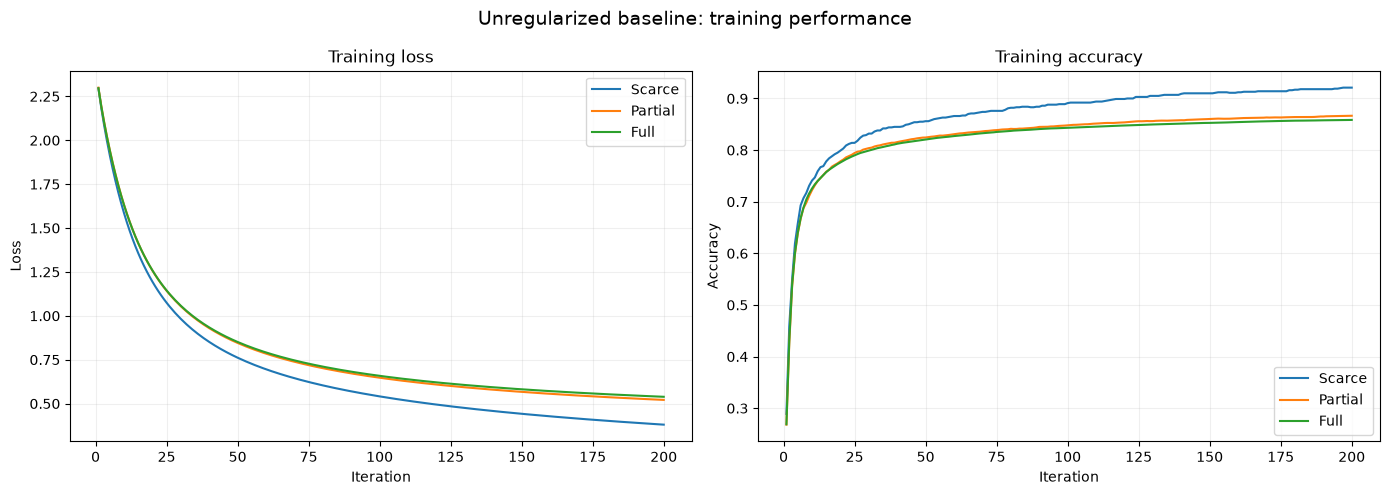

In [19]:
# ============================================================
# Training loss and accuracy
# ============================================================

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Loss
for regime_name, losses in baseline_losses.items():
    axs[0].plot(
        range(1, len(losses) + 1),
        losses,
        label=regime_name
    )

axs[0].set_title("Training loss")
axs[0].set_xlabel("Iteration")
axs[0].set_ylabel("Loss")
axs[0].grid(alpha=0.2)
axs[0].legend()

# Accuracy
for regime_name, accuracies in baseline_accuracies.items():
    axs[1].plot(
        range(1, len(accuracies) + 1),
        accuracies,
        label=regime_name
    )

axs[1].set_title("Training accuracy")
axs[1].set_xlabel("Iteration")
axs[1].set_ylabel("Accuracy")
axs[1].grid(alpha=0.2)
axs[1].legend()

fig.suptitle(
    "Unregularized baseline: training performance",
    fontsize=14
)

plt.tight_layout()
plt.show()

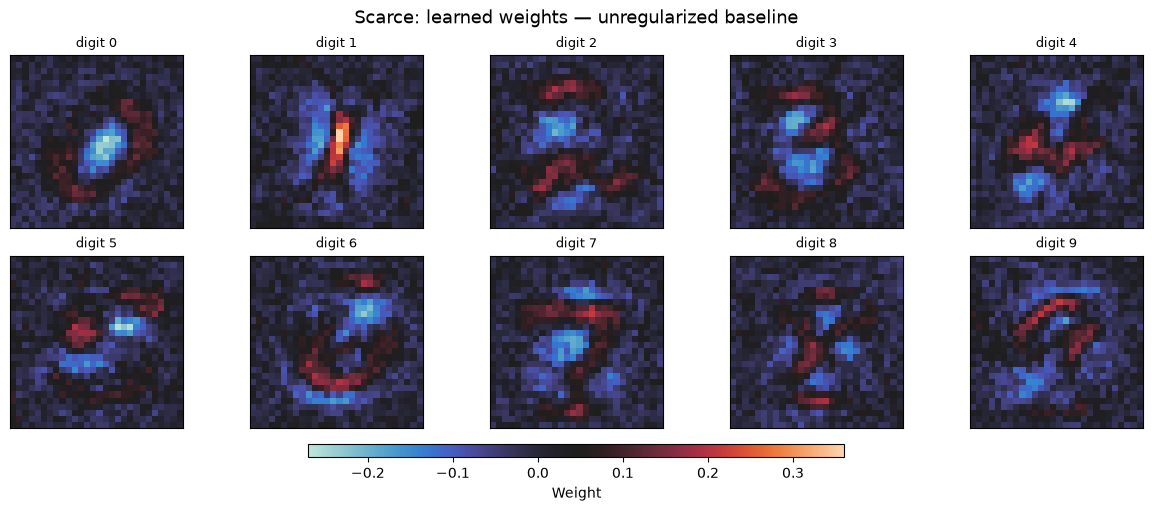

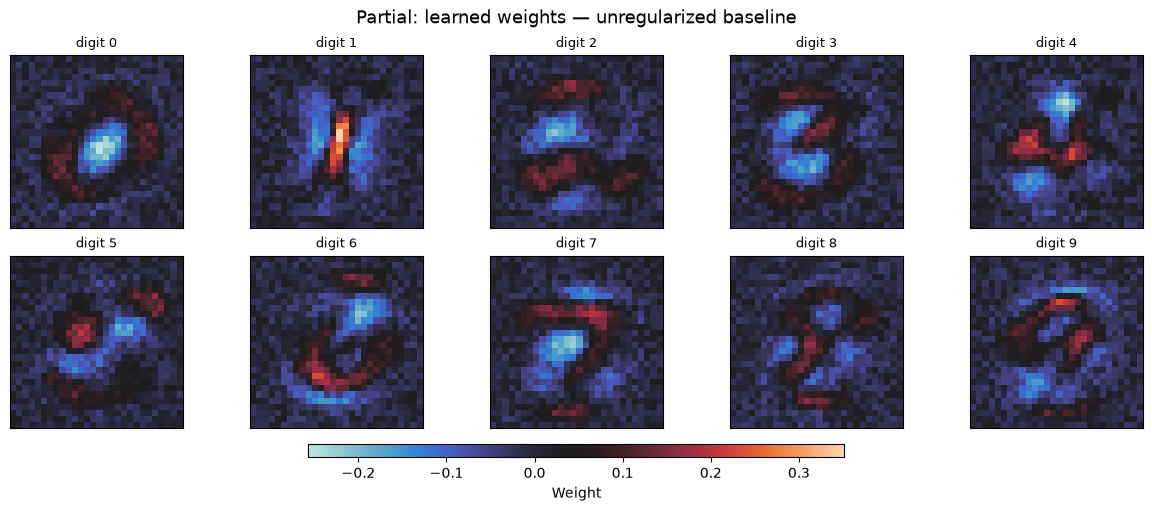

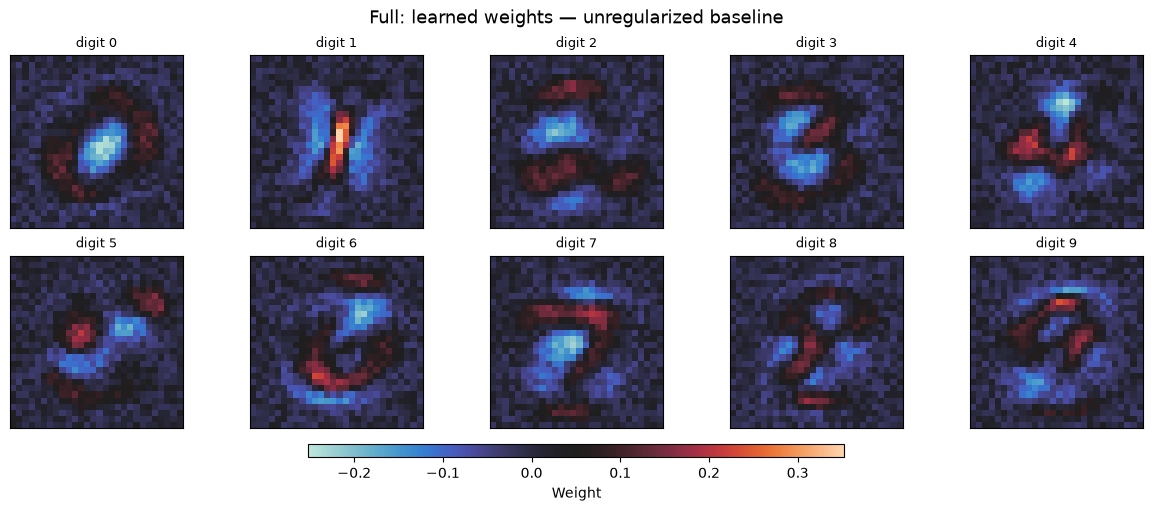

In [20]:
# ============================================================
# Extract learned weights
# ============================================================

baseline_weights = {}

for regime_name, model in baseline_models.items():

    weights = (
        model.linear.weight
        .detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    baseline_weights[regime_name] = weights

for regime_name, weights in baseline_weights.items():

    plot_weights(
        weights,
        title=f"{regime_name}: learned weights — unregularized baseline"
    )

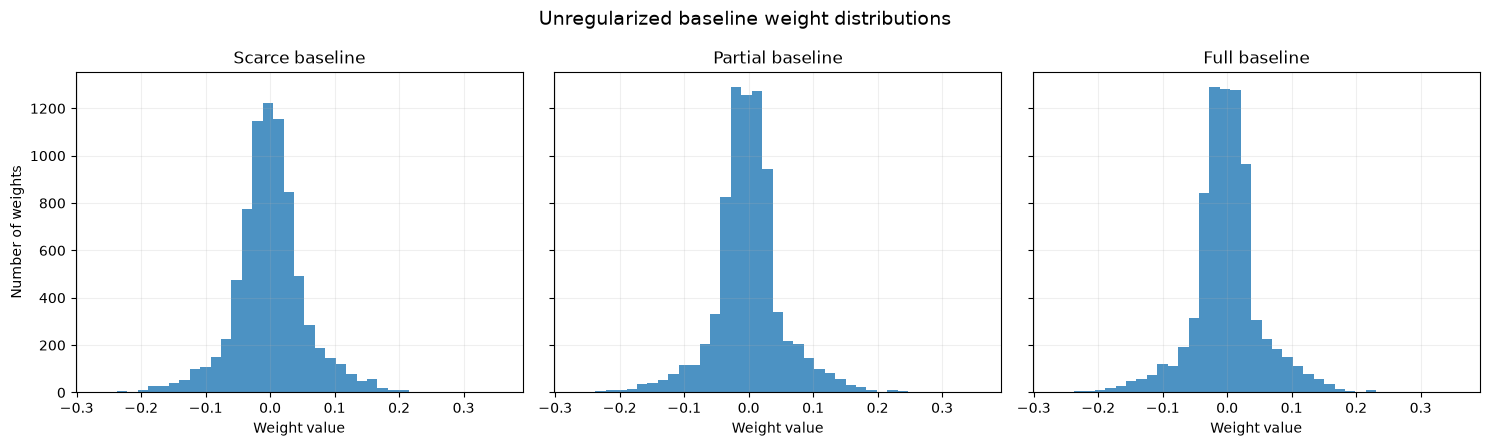

In [21]:
# ============================================================
# Baseline weight distributions across data regimes
# ============================================================

# Flatten all weights from each model
weight_distributions = {
    regime: model.linear.weight.detach().cpu().numpy().ravel()
    for regime, model in baseline_models.items()
}

# Common x-axis range for fair comparison
all_weights = np.concatenate(list(weight_distributions.values()))

x_min = all_weights.min()
x_max = all_weights.max()

# Same bins for all regimes
bins = np.linspace(x_min, x_max, 40)

fig, axs = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True
)

for ax, (regime, weights) in zip(
    axs,
    weight_distributions.items()
):
    ax.hist(
        weights,
        bins=bins,
        alpha=0.8
    )

    ax.set_title(f"{regime} baseline")
    ax.set_xlabel("Weight value")
    ax.grid(alpha=0.2)

axs[0].set_ylabel("Number of weights")

fig.suptitle(
    "Unregularized baseline weight distributions",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [22]:
for regime, weights in weight_distributions.items():
    print(
        f"{regime:<8} | "
        f"mean = {weights.mean():.4f} | "
        f"std = {weights.std():.4f} | "
        f"min = {weights.min():.4f} | "
        f"max = {weights.max():.4f} | "
        f"mean |w| = {np.abs(weights).mean():.4f}"
    )

Scarce   | mean = -0.0000 | std = 0.0562 | min = -0.2701 | max = 0.3605 | mean |w| = 0.0400
Partial  | mean = -0.0000 | std = 0.0540 | min = -0.2568 | max = 0.3517 | mean |w| = 0.0375
Full     | mean = -0.0000 | std = 0.0535 | min = -0.2518 | max = 0.3527 | mean |w| = 0.0371


> **Questão 2.3**
>
> Examine as imagens dos pesos de cada modelo de referência. Como você explica os valores dos pesos no mapa de calor e quais padrões eles apresentam?
>
> Compare os modelos: em que eles diferem?

**1. Acurácia e perda de treinamento ao longo das iterações**

- A otimização nos três regimes ocorre de forma suave: a perda diminui monotonicamente e a acurácia de treinamento aumenta ao longo das 200 iterações.
- O regime de dados escassos (Scarce) se distancia dos outros dois desde cedo e atinge o melhor ajuste aos dados de treinamento, com acurácia final de **0,9210** e perda final de **0,3801**.
- Os regimes de dados parciais (Partial) e completos (Full) permanecem muito próximos durante todo o treinamento, terminando com acurácia/perda de **0,8665** / **0,5210** e **0,8584** / **0,5388**, respectivamente.

**2. Imagens dos pesos (mapas de calor)**

- Cada linha de $W$ é uma imagem 28×28: pesos positivos aumentam o logit daquela classe; negativos o reduzem. Os mapas recuperam a silhueta média do dígito (traços claros/escuros alinhados à geometria da classe).
- **Scarce** tem pesos com amplitudes maiores e aparência mais “ruidosa”/irregular — compatível com melhor ajuste ao treino e maior risco de sobreajuste a padrões espúrios da corrupção.
- **Partial** e **Full** têm mapas mais estáveis e semelhantes entre si, com contraste um pouco mais suave; a distribuição dos pesos é mais concentrada perto de zero que no Scarce.
- Diferença principal entre regimes: não é um padrão de classe diferente, e sim **quanto** o modelo exagera coeficientes quando há poucos dados (Scarce) versus quando há muitos (Partial/Full).


---

## Parte 3. Regularização

**(2,0 pontos)**

Agora introduzimos a regularização e exploramos uma grade de valores de $\lambda$ para as penalidades L1 e L2.

Seu **único critério de decisão** nesta parte é a acurácia de validação cruzada calculada sobre os dados de treinamento corrompidos, exatamente o que você teria em um cenário real sem acesso a um conjunto de teste sem corrupção ou com uma corrupção diferente.

Para cada configuração (regime de dados × tipo de regularização × $\lambda$), use validação cruzada com K partições (K-fold) para estimar a acurácia de validação (informe a média **e** o desvio padrão entre as partições).
Em seguida, para cada regularizador, **selecione o melhor $\lambda$** por validação cruzada (CV) e treine um modelo final com todo o conjunto de treinamento daquele regime.

Treine e armazene também um modelo para **cada** $\lambda$ da grade no regime de dados completos (Full-data): eles serão usados apenas nos gráficos de diagnóstico da Parte 4, e não na seleção.

> **Tarefa de decisão:** Informe, para cada regularizador e regime de dados, qual $\lambda$ você selecionou e por quê.
Examine as imagens dos pesos dos modelos escolhidos e descreva o que observa.

### Protocolo dos experimentos

- **3 folds estratificados**, embaralhados com semente 42. Todos os candidatos usam os mesmos cortes e a mesma inicialização dentro de cada fold.
- Grade inicial para L1 e L2: $\lambda\in\{0,10^{-5},10^{-4},10^{-3},10^{-2},10^{-1}\}$; 200 iterações de SGD completo e `lr=0.1`, como nos modelos de referência. Os resultados valem para esse orçamento de treinamento; não pressupõem convergência ao mínimo de cada objetivo.
- Dividimos os dados brutos antes de aplicar `preprocess_images` separadamente a treino e validação. A transformação `/255` é fixa e não estima estatísticas. Qualquer transformação futura que aprenda estatísticas deve ser ajustada somente no treino de cada fold.
- Seleção exclusivamente pela **maior acurácia média de validação**; empate exato é resolvido pelo menor $\lambda$. O desvio padrão amostral entre folds (`ddof=1`) acompanha a média; não é um intervalo de confiança.
- Retreinamos os selecionados em todos os dados do respectivo regime. No Full, guardamos também um modelo por $\lambda$ para diagnósticos futuros. Nenhum conjunto de teste é carregado aqui.
- A fração $|w|<10^{-3}$ mede pesos **próximos de zero**: SGD com subgradiente e passo fixo não garante zeros exatos para L1. As perdas de treinamento incluem a penalização.

Os boxplots usam escalas alinhadas. O diagrama do slide é um caso particular de regressão linear; aqui mostramos os coeficientes efetivamente aprendidos pela regressão logística.


In [23]:
from pathlib import Path
from sklearn.model_selection import StratifiedKFold

cv_n_splits = 3
lambda_grid = np.array([0.0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1])
cv_n_iter, cv_lr = n_iter, lr
regularizers = {"L1": loss_l1, "L2": loss_l2}
cv_raw_datasets = {
    "Scarce": (X_scarce, y_scarce),
    "Partial": (X_partial, y_partial),
    "Full": (X_full, y_full),
}
results_dir = Path("resultados_parte3")
figures_dir = Path("imagens_respostas")
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)
torch.set_num_threads(min(4, torch.get_num_threads()))

def evaluate_training_model(model, X, y):
    model.eval()
    with torch.no_grad():
        return accuracy(model(X), y)

def new_cv_model(n_features, fold=0):
    # Identical initialization across penalties and lambda values in a fold.
    torch.manual_seed(seed + fold)
    return LinearModel(n_features=n_features, n_classes=10)

def save_part3_figure(fig, name):
    fig.savefig(figures_dir / name, dpi=130, bbox_inches="tight")
    plt.show()


In [24]:
# K-fold cross-validation: corrupted training data only.
#
# ANOTAÇÃO (entrega / tempo): uma execução anterior desta célula foi interrompida
# (KeyboardInterrupt no meio dos folds). Os resultados finais já estão salvos em
# resultados_parte3/ (cv_folds.csv, cv_results.csv, selected_cv.csv, modelos_parte3.pt).

#
cv_fold_rows = []
for regime_name, (X_raw, y_raw) in cv_raw_datasets.items():
    splitter = StratifiedKFold(n_splits=cv_n_splits, shuffle=True, random_state=seed)
    for fold, (train_idx, val_idx) in enumerate(splitter.split(X_raw, y_raw)):
        assert not np.intersect1d(train_idx, val_idx).size
        X_train_fold = torch.from_numpy(preprocess_images(X_raw[train_idx]))
        X_val_fold = torch.from_numpy(preprocess_images(X_raw[val_idx]))
        y_train_fold = torch.as_tensor(y_raw[train_idx], dtype=torch.long)
        y_val_fold = torch.as_tensor(y_raw[val_idx], dtype=torch.long)
        # lambda=0 gives the same model for both penalties: fit it only once.
        unregularized_scores = None
        for regularizer_name, objective in regularizers.items():
            for lambda_value in lambda_grid:
                lambda_value = float(lambda_value)
                if lambda_value == 0 and unregularized_scores is not None:
                    train_acc, val_acc = unregularized_scores
                else:
                    model = new_cv_model(X_train_fold.shape[1], fold)
                    train(model, X_train_fold, y_train_fold, n_iter=cv_n_iter,
                          loss_fn=objective, lambda_reg=lambda_value, lr=cv_lr)
                    train_acc = evaluate_training_model(model, X_train_fold, y_train_fold)
                    val_acc = evaluate_training_model(model, X_val_fold, y_val_fold)
                    if lambda_value == 0:
                        unregularized_scores = (train_acc, val_acc)
                cv_fold_rows.append({
                    "regime": regime_name, "regularizer": regularizer_name,
                    "lambda": lambda_value, "fold": fold + 1,
                    "n_train": len(train_idx), "n_val": len(val_idx),
                    "train_accuracy": train_acc, "val_accuracy": val_acc,
                })
            print(f"{regime_name} | fold {fold + 1}/{cv_n_splits} | {regularizer_name} OK", flush=True)
        pd.DataFrame(cv_fold_rows).to_csv(results_dir / "cv_folds.csv", index=False)

cv_folds = pd.DataFrame(cv_fold_rows)
cv_results = cv_folds.groupby(
    ["regime", "regularizer", "lambda"], sort=False, as_index=False
).agg(cv_mean=("val_accuracy", "mean"), cv_std=("val_accuracy", "std"),
      train_mean=("train_accuracy", "mean"))
cv_results["train_val_gap"] = cv_results["train_mean"] - cv_results["cv_mean"]
selected_rows = []
for regime_name in cv_raw_datasets:
    for regularizer_name in regularizers:
        candidates = cv_results[(cv_results["regime"] == regime_name)
                                & (cv_results["regularizer"] == regularizer_name)]
        best = candidates.sort_values(["cv_mean", "lambda"], ascending=[False, True]).iloc[0]
        selected_rows.append(best.to_dict())
selected_cv = pd.DataFrame(selected_rows)
selected_lambdas = {(row["regime"], row["regularizer"]): float(row["lambda"])
                    for row in selected_rows}
cv_results.to_csv(results_dir / "cv_results.csv", index=False)
selected_cv.to_csv(results_dir / "selected_cv.csv", index=False)
print("Todas as configuracoes (acuracias em fracao):")
display(cv_results.round(5))
print("Selecao por maior media de CV; desempate pelo menor lambda:")
display(selected_cv[["regime", "regularizer", "lambda", "cv_mean", "cv_std"]].round(5))


Scarce | fold 1/3 | L1 OK
Scarce | fold 1/3 | L2 OK
Scarce | fold 2/3 | L1 OK
Scarce | fold 2/3 | L2 OK
Scarce | fold 3/3 | L1 OK
Scarce | fold 3/3 | L2 OK
Partial | fold 1/3 | L1 OK
Partial | fold 1/3 | L2 OK
Partial | fold 2/3 | L1 OK
Partial | fold 2/3 | L2 OK
Partial | fold 3/3 | L1 OK
Partial | fold 3/3 | L2 OK
Full | fold 1/3 | L1 OK
Full | fold 1/3 | L2 OK
Full | fold 2/3 | L1 OK
Full | fold 2/3 | L2 OK
Full | fold 3/3 | L1 OK
Full | fold 3/3 | L2 OK
Todas as configuracoes (acuracias em fracao):


,regime,regularizer,lambda,cv_mean,cv_std,train_mean,train_val_gap
0,Scarce,L1,0.00000,0.81501,0.01227,0.94950,0.13449
1,Scarce,L1,0.00001,0.81501,0.01227,0.94900,0.13399
2,Scarce,L1,0.00010,0.81701,0.01289,0.94800,0.13099
3,Scarce,L1,0.00100,0.81701,0.01289,0.93800,0.12099
4,Scarce,L1,0.01000,0.77601,0.01096,0.84200,0.06599
5,Scarce,L1,0.10000,0.30095,0.04595,0.32304,0.02209
6,Scarce,L2,0.00000,0.81501,0.01227,0.94950,0.13449
7,Scarce,L2,0.00001,0.81501,0.01227,0.94950,0.13449
8,Scarce,L2,0.00010,0.81501,0.01227,0.94900,0.13399
9,Scarce,L2,0.00100,0.81301,0.01117,0.94900,0.13599


Selecao por maior media de CV; desempate pelo menor lambda:


,regime,regularizer,lambda,cv_mean,cv_std
0,Scarce,L1,0.0001,0.81701,0.01289
1,Scarce,L2,0.0000,0.81501,0.01227
2,Partial,L1,0.0000,0.85570,0.00801
3,Partial,L2,0.0000,0.85570,0.00801
4,Full,L1,0.0000,0.85693,0.00220
5,Full,L2,0.0000,0.85693,0.00220


In [25]:
# Refit selected models and keep every Full-data lambda for Part 4.
selected_models = {regime: {"Baseline": baseline_models[regime]} for regime in cv_raw_datasets}
full_models_by_lambda = {name: {} for name in regularizers}
selected_training_histories = {}
for regime_name, (X_regime, y_regime) in datasets_torch.items():
    for regularizer_name, objective in regularizers.items():
        best_lambda = selected_lambdas[(regime_name, regularizer_name)]
        values_to_fit = lambda_grid if regime_name == "Full" else [best_lambda]
        for lambda_value in values_to_fit:
            lambda_value = float(lambda_value)
            if lambda_value == 0:
                model = baseline_models[regime_name]
                losses = baseline_losses[regime_name]
                accuracies = baseline_accuracies[regime_name]
            else:
                model = new_cv_model(X_regime.shape[1])
                losses, accuracies = train(model, X_regime, y_regime, n_iter=cv_n_iter,
                    loss_fn=objective, lambda_reg=lambda_value, lr=cv_lr)
            if regime_name == "Full":
                full_models_by_lambda[regularizer_name][lambda_value] = model
            if lambda_value == best_lambda:
                selected_models[regime_name][regularizer_name] = model
                selected_training_histories[(regime_name, regularizer_name)] = {
                    "loss": losses, "accuracy": accuracies}
        print(f"Refit: {regime_name} | {regularizer_name} OK", flush=True)

weight_stats_rows = []
for regularizer_name, models in full_models_by_lambda.items():
    for lambda_value, model in models.items():
        weights = model.linear.weight.detach().cpu().numpy()
        weight_stats_rows.append({
            "regularizer": regularizer_name, "lambda": lambda_value,
            "near_zero_fraction": float((np.abs(weights) < 1e-3).mean()),
            "exact_zero_fraction": float((weights == 0).mean()),
            "mean_abs_weight": float(np.abs(weights).mean()),
            "l2_norm": float(np.linalg.norm(weights)),
        })
full_weight_stats = pd.DataFrame(weight_stats_rows)
full_weight_stats.to_csv(results_dir / "full_weight_stats.csv", index=False)
torch.save({
    "config": {"seed": seed, "n_splits": cv_n_splits, "n_iter": cv_n_iter,
               "lr": cv_lr, "lambda_grid": list(np.asarray(lambda_grid).tolist())},
    "selected_lambdas": selected_lambdas,
    "selected_state_dicts": {regime: {name: model.state_dict() for name, model in models.items()}
                            for regime, models in selected_models.items()},
    "full_state_dicts": {name: {value: model.state_dict() for value, model in models.items()}
                        for name, models in full_models_by_lambda.items()},
}, results_dir / "modelos_parte3.pt")
print("Modelos, configuracao e tabelas salvos em", results_dir.resolve())


Refit: Scarce | L1 OK
Refit: Scarce | L2 OK
Refit: Partial | L1 OK
Refit: Partial | L2 OK
Refit: Full | L1 OK
Refit: Full | L2 OK
Modelos, configuracao e tabelas salvos em /home/pedro/programas_etc/MC886/trab2/resultados_parte3


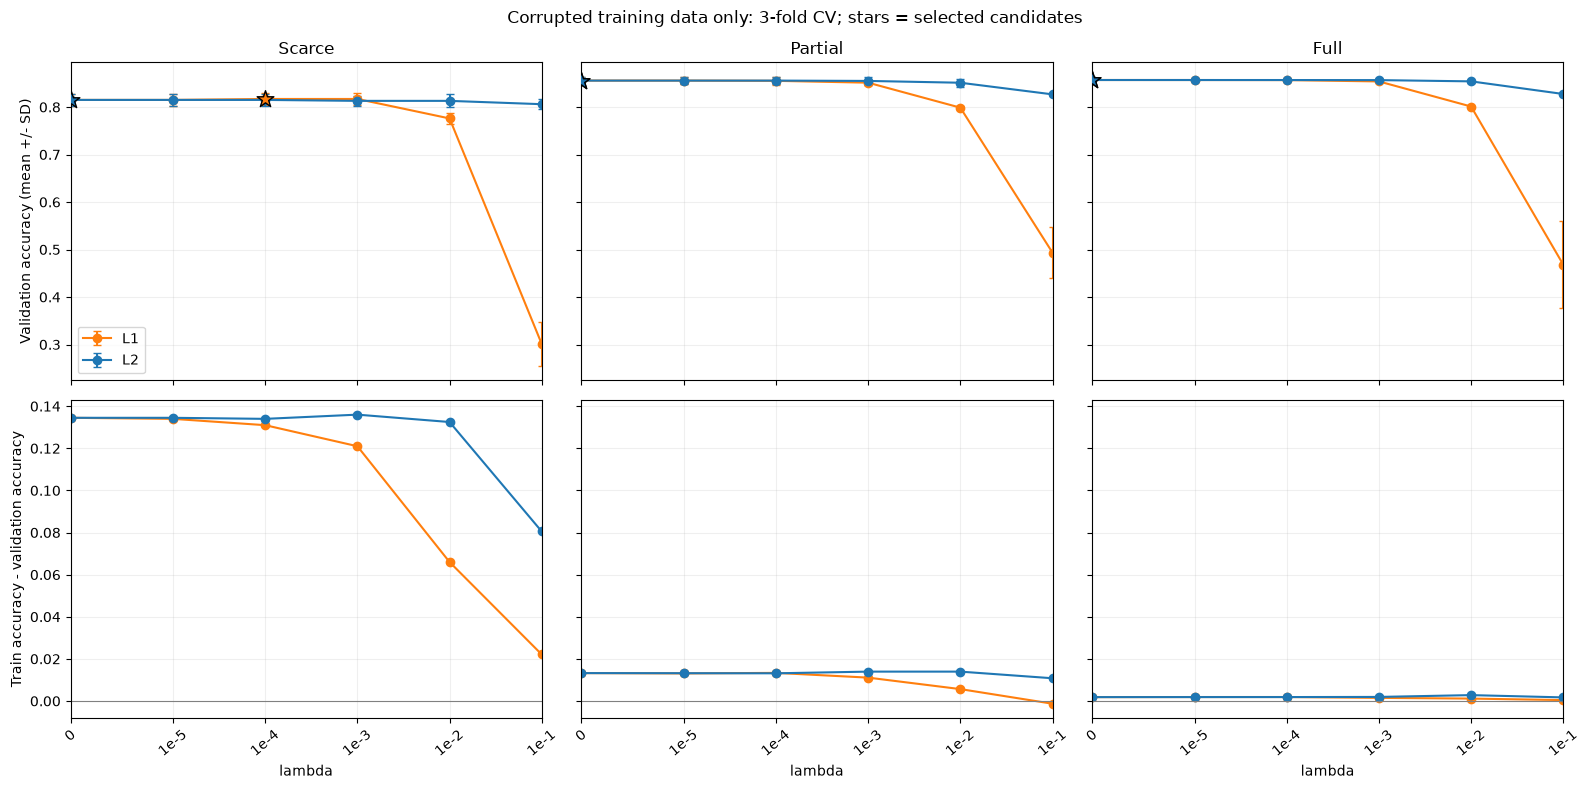

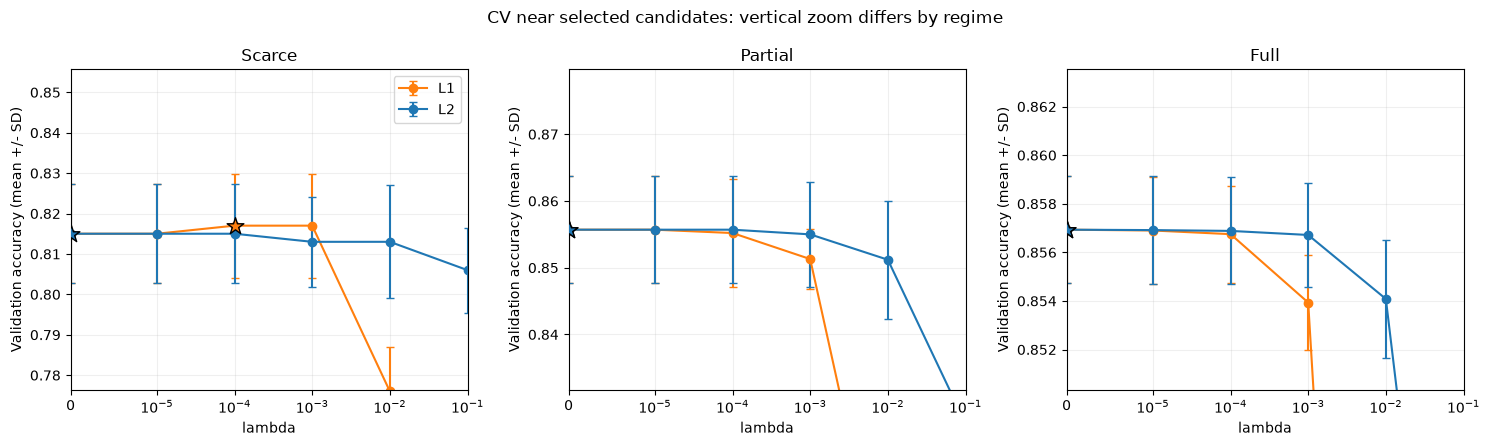

In [26]:
# Same axes for all regimes; bars show +/- one fold standard deviation.
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey="row")
colors = {"L1": "tab:orange", "L2": "tab:blue"}
for col, regime_name in enumerate(cv_raw_datasets):
    for regularizer_name in regularizers:
        rows = cv_results[(cv_results["regime"] == regime_name)
            & (cv_results["regularizer"] == regularizer_name)].sort_values("lambda")
        axes[0, col].errorbar(rows["lambda"], rows["cv_mean"], yerr=rows["cv_std"],
            marker="o", capsize=3, color=colors[regularizer_name], label=regularizer_name)
        best_lambda = selected_lambdas[(regime_name, regularizer_name)]
        best = rows[rows["lambda"] == best_lambda].iloc[0]
        axes[0, col].scatter(best_lambda, best["cv_mean"], marker="*", s=160,
            color=colors[regularizer_name], edgecolor="black", zorder=5)
        axes[1, col].plot(rows["lambda"], rows["train_val_gap"], "o-",
            color=colors[regularizer_name], label=regularizer_name)
    axes[0, col].set_title(regime_name)
    axes[1, col].axhline(0, color="gray", linewidth=0.8)
    axes[1, col].set_xlabel("lambda")
    for ax in axes[:, col]:
        ax.set_xscale("symlog", linthresh=1e-5)
        ax.set_xlim(0, float(lambda_grid[-1]))
        ax.set_xticks(lambda_grid)
        ax.set_xticklabels(["0", "1e-5", "1e-4", "1e-3", "1e-2", "1e-1"], rotation=40)
        ax.grid(alpha=0.2)
axes[0, 0].set_ylabel("Validation accuracy (mean +/- SD)")
axes[1, 0].set_ylabel("Train accuracy - validation accuracy")
axes[0, 0].legend()
fig.suptitle("Corrupted training data only: 3-fold CV; stars = selected candidates")
fig.tight_layout()
save_part3_figure(fig, "parte3_cv_acuracia_gap.png")


# Zoom each regime near its selected candidates to inspect neighboring means/SDs.
# The overview above keeps common axes; this zoom explicitly uses different y limits.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, regime_name in zip(axes, cv_raw_datasets):
    chosen = selected_cv[selected_cv["regime"] == regime_name]
    margin = max(3 * chosen["cv_std"].max(), 0.005)
    for regularizer_name in regularizers:
        rows = cv_results[(cv_results["regime"] == regime_name)
            & (cv_results["regularizer"] == regularizer_name)].sort_values("lambda")
        ax.errorbar(rows["lambda"], rows["cv_mean"], yerr=rows["cv_std"],
            marker="o", capsize=3, color=colors[regularizer_name], label=regularizer_name)
        best_lambda = selected_lambdas[(regime_name, regularizer_name)]
        best = rows[rows["lambda"] == best_lambda].iloc[0]
        ax.scatter(best_lambda, best["cv_mean"], marker="*", s=160,
            color=colors[regularizer_name], edgecolor="black", zorder=5)
    ax.set_ylim(chosen["cv_mean"].min() - margin, chosen["cv_mean"].max() + margin)
    ax.set_xscale("symlog", linthresh=1e-5)
    ax.set_xlim(0, float(lambda_grid[-1]))
    ax.set_xlabel("lambda")
    ax.set_ylabel("Validation accuracy (mean +/- SD)")
    ax.set_title(regime_name)
    ax.grid(alpha=0.2)
axes[0].legend()
fig.suptitle("CV near selected candidates: vertical zoom differs by regime")
fig.tight_layout()
save_part3_figure(fig, "parte3_cv_zoom.png")


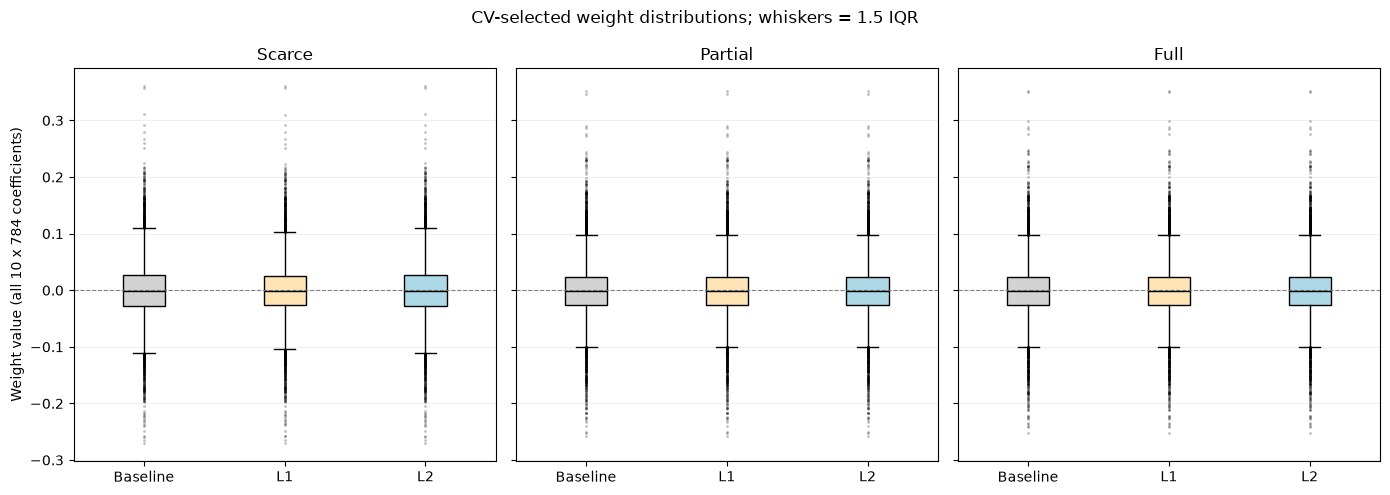

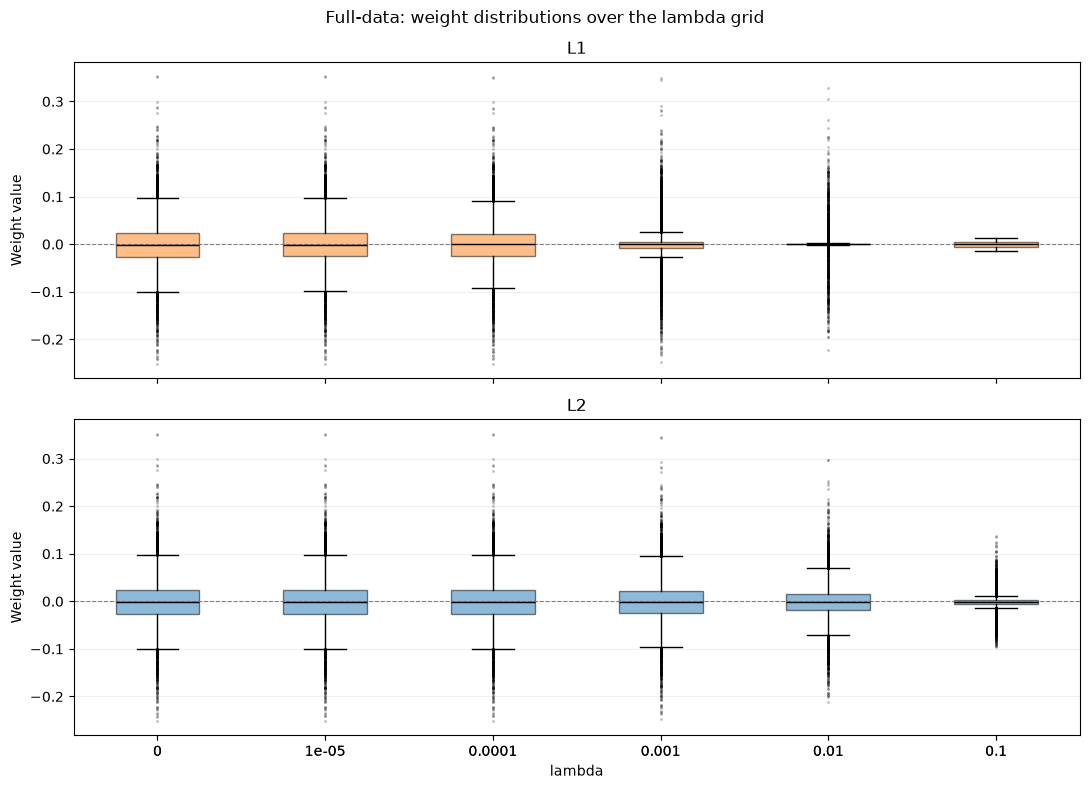

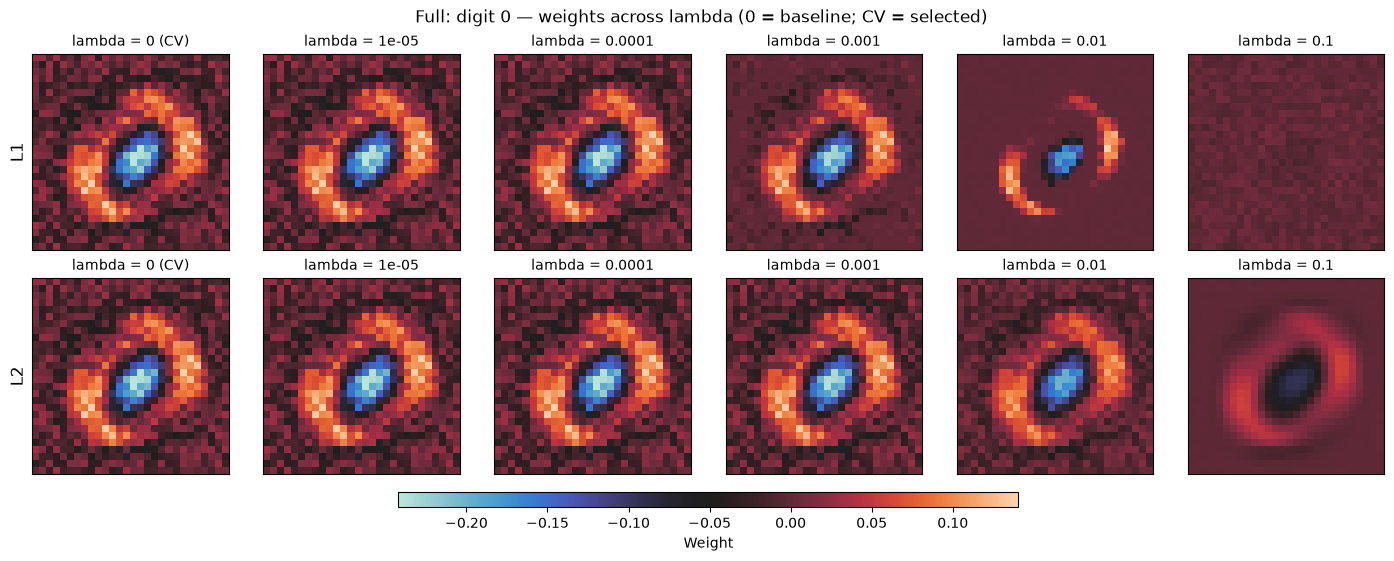

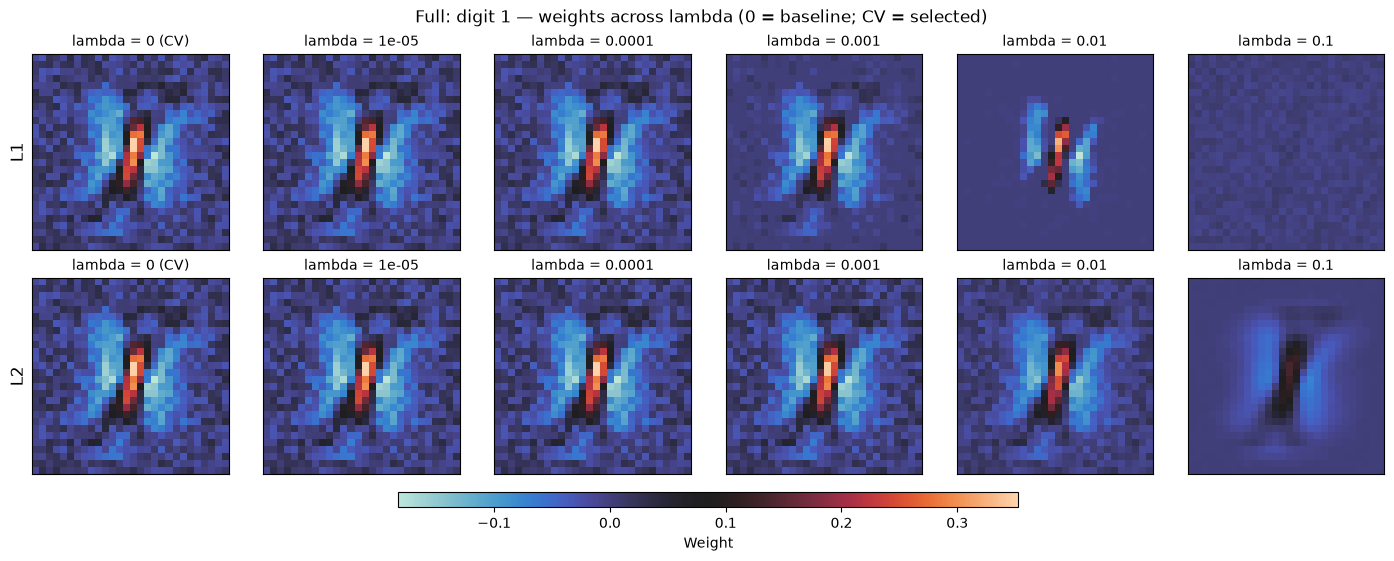

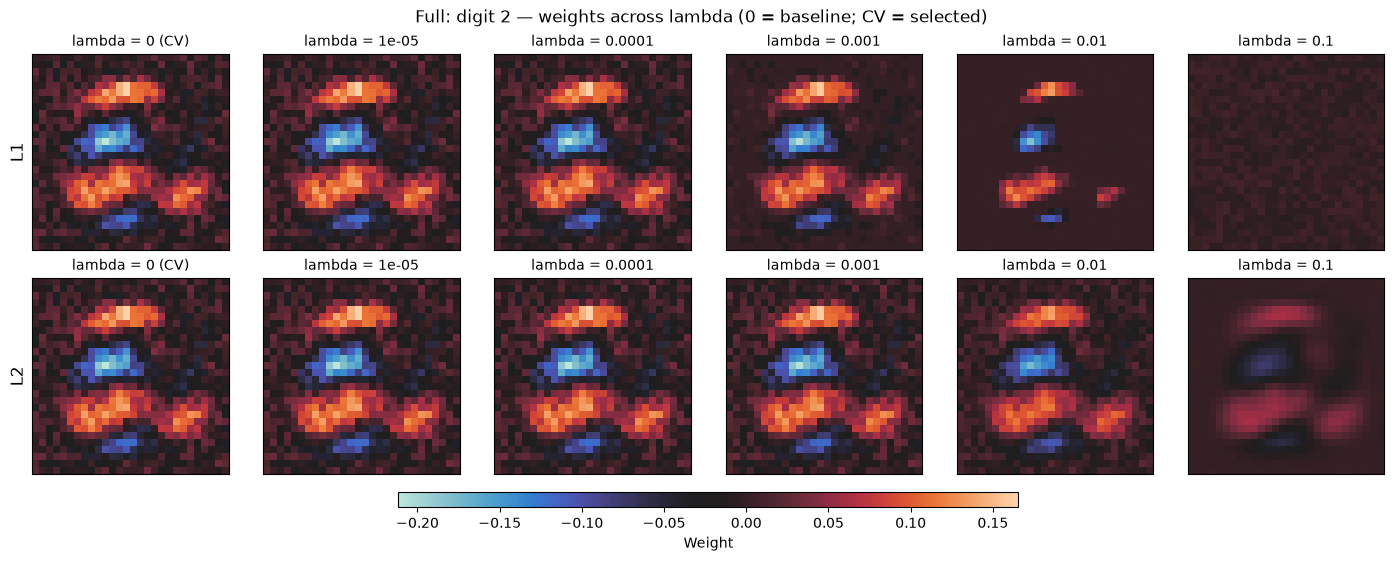

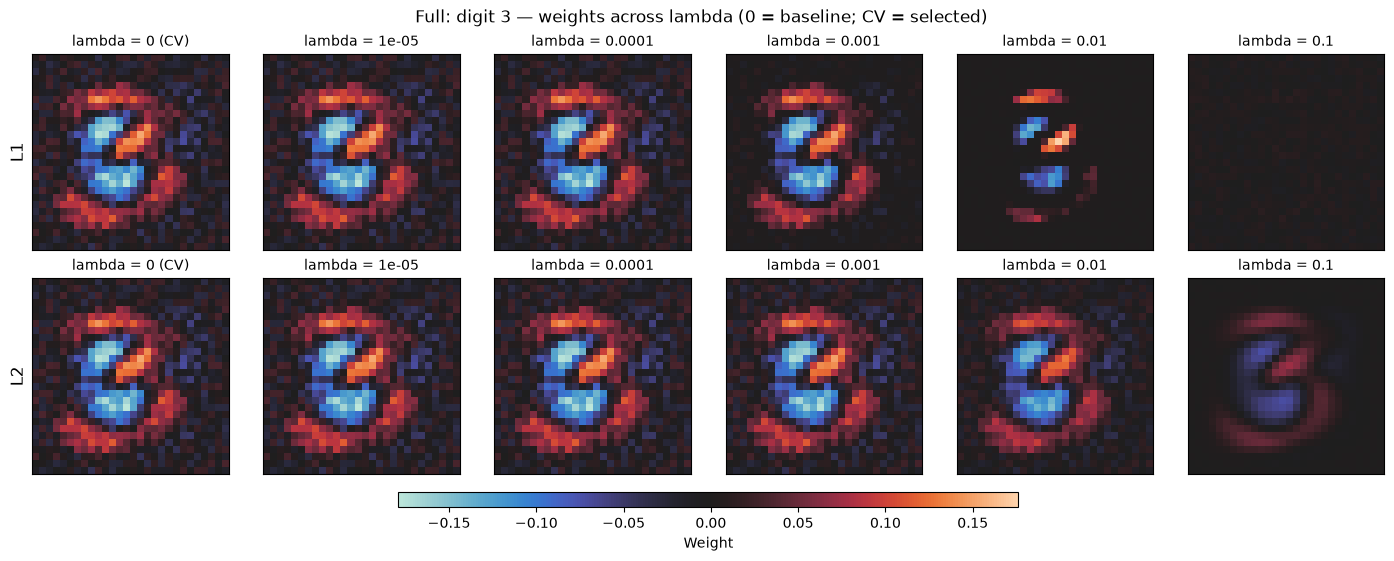

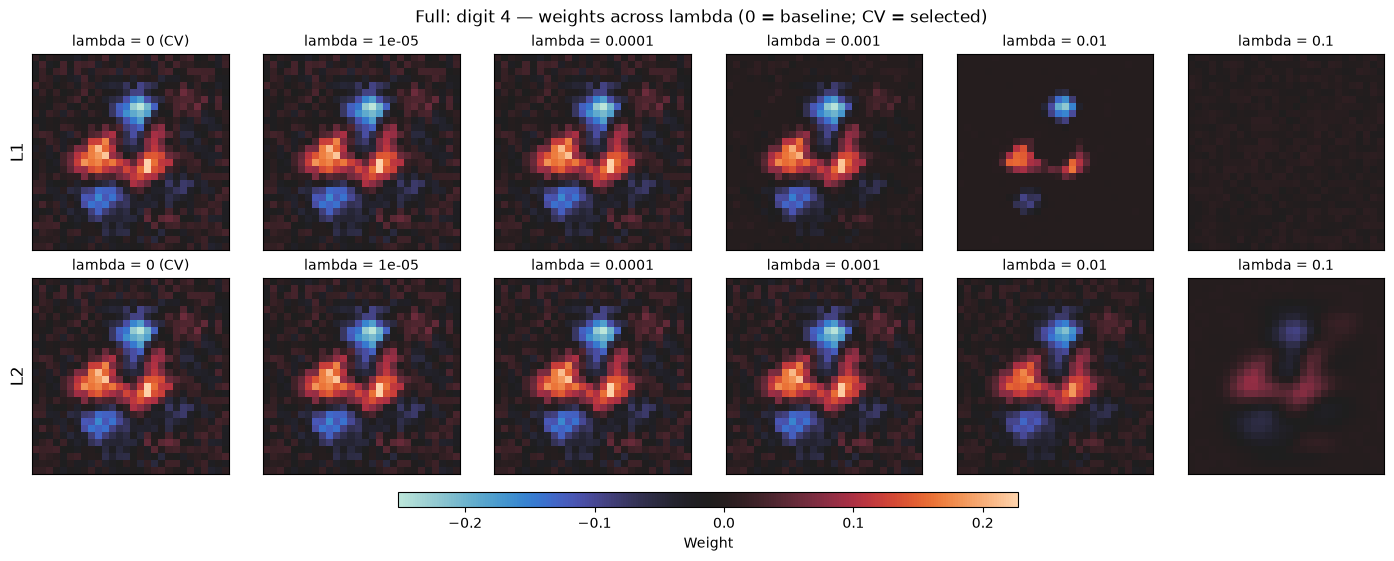

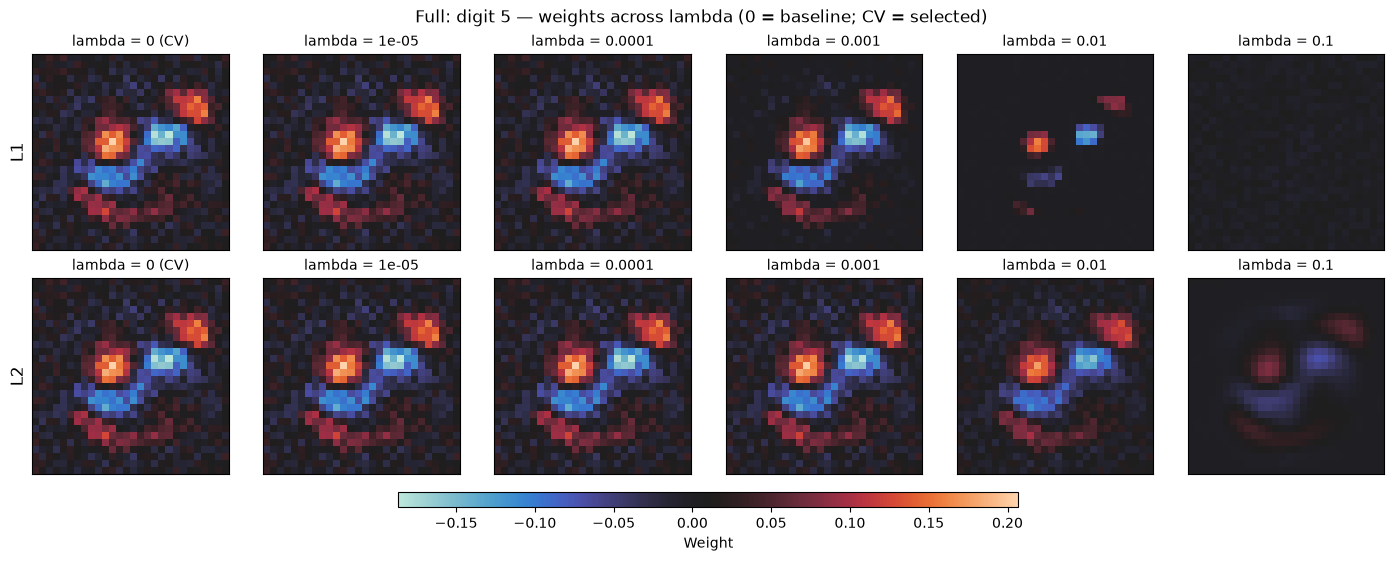

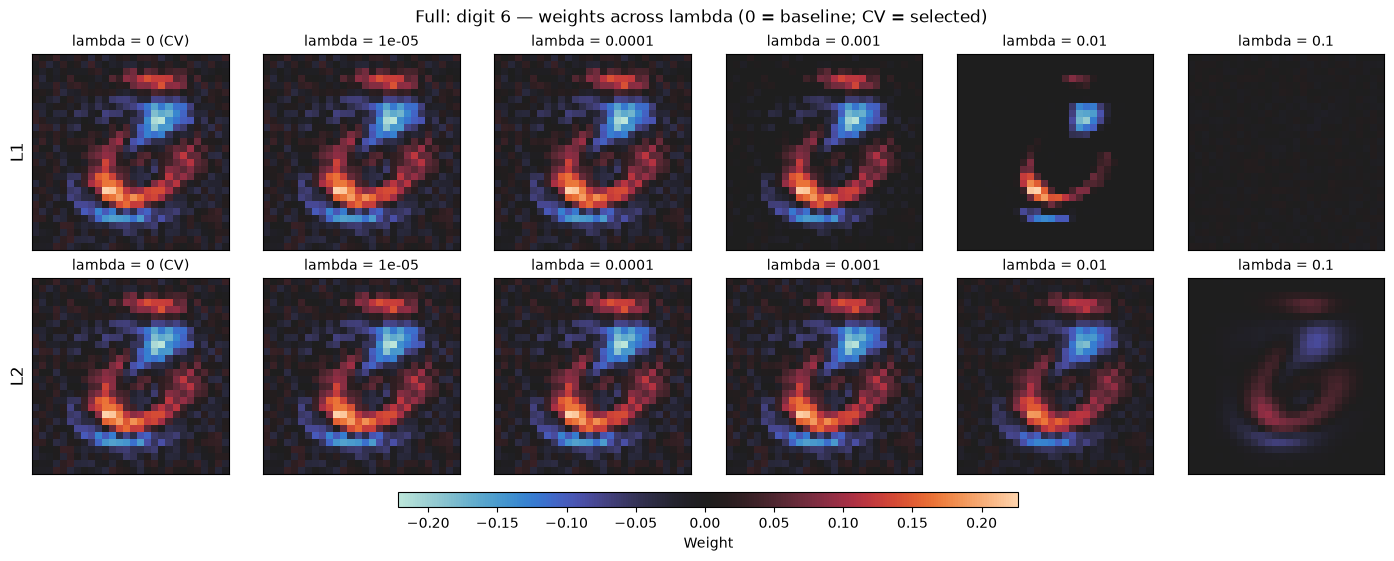

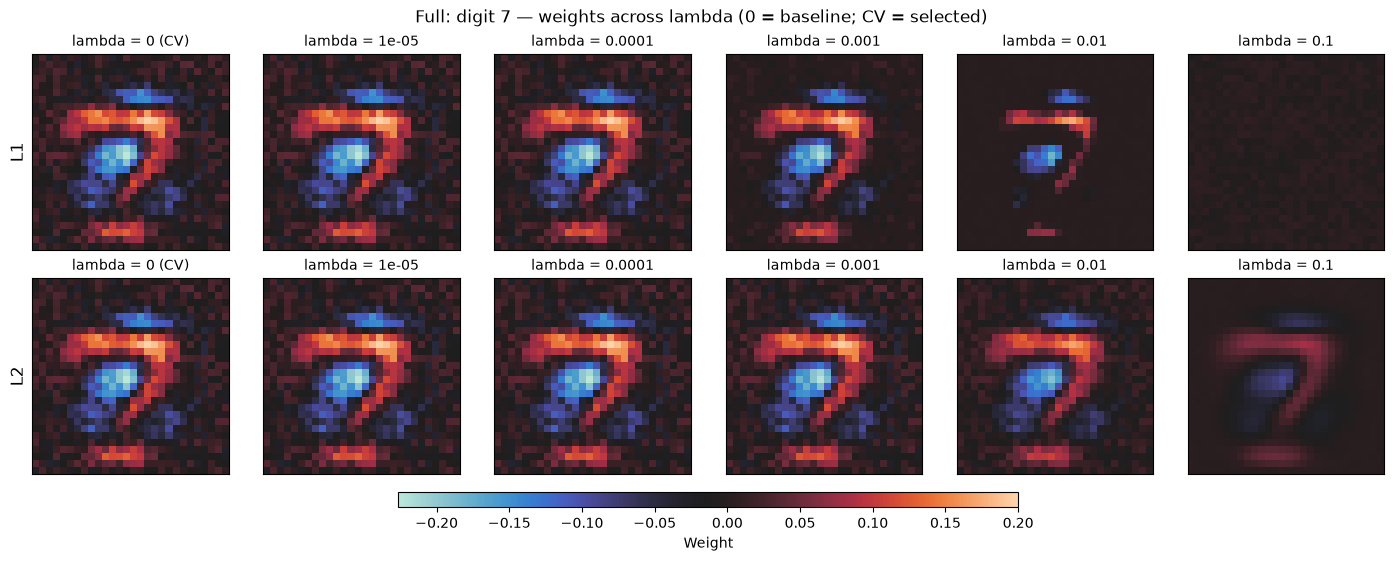

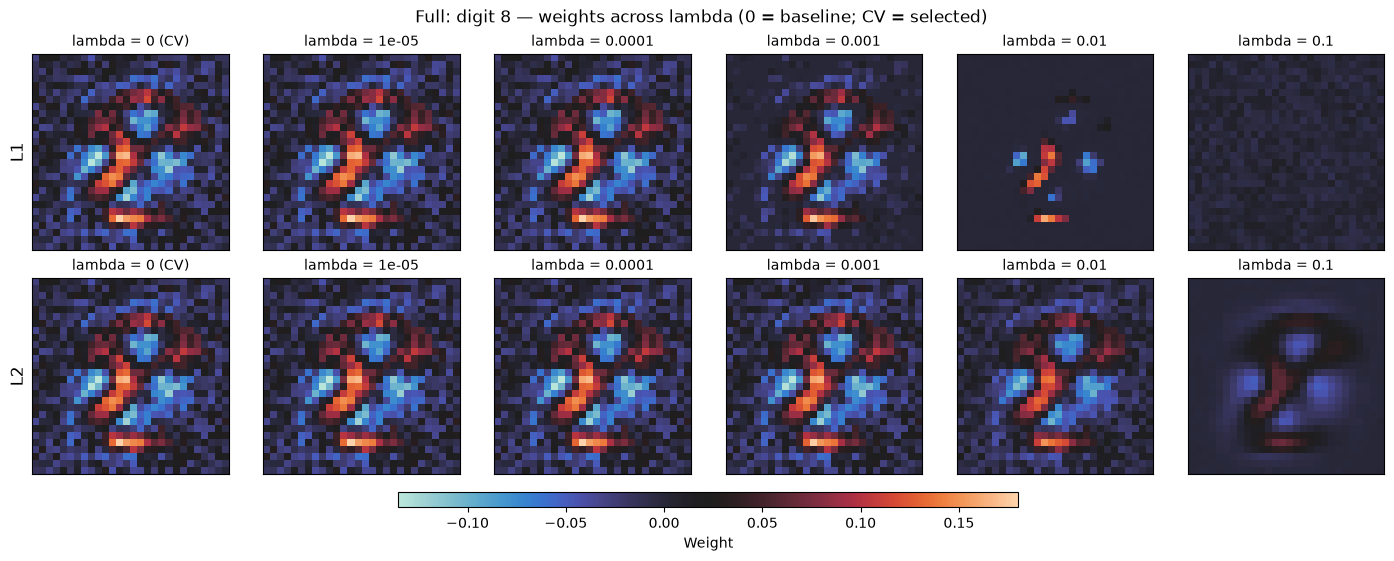

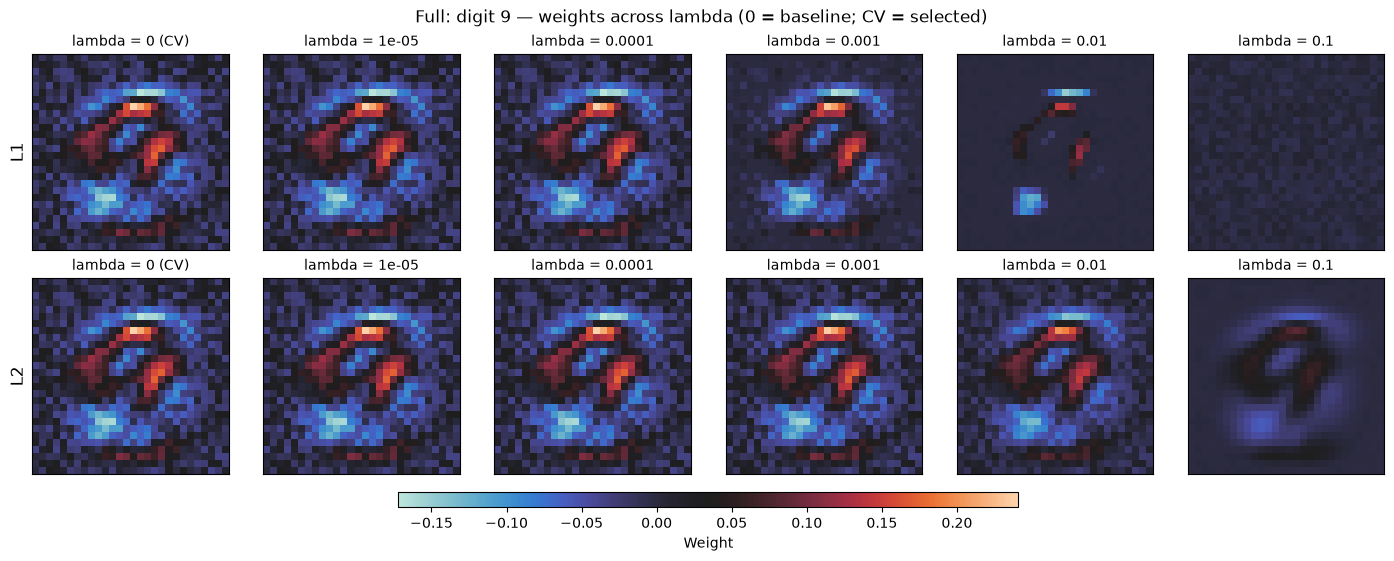

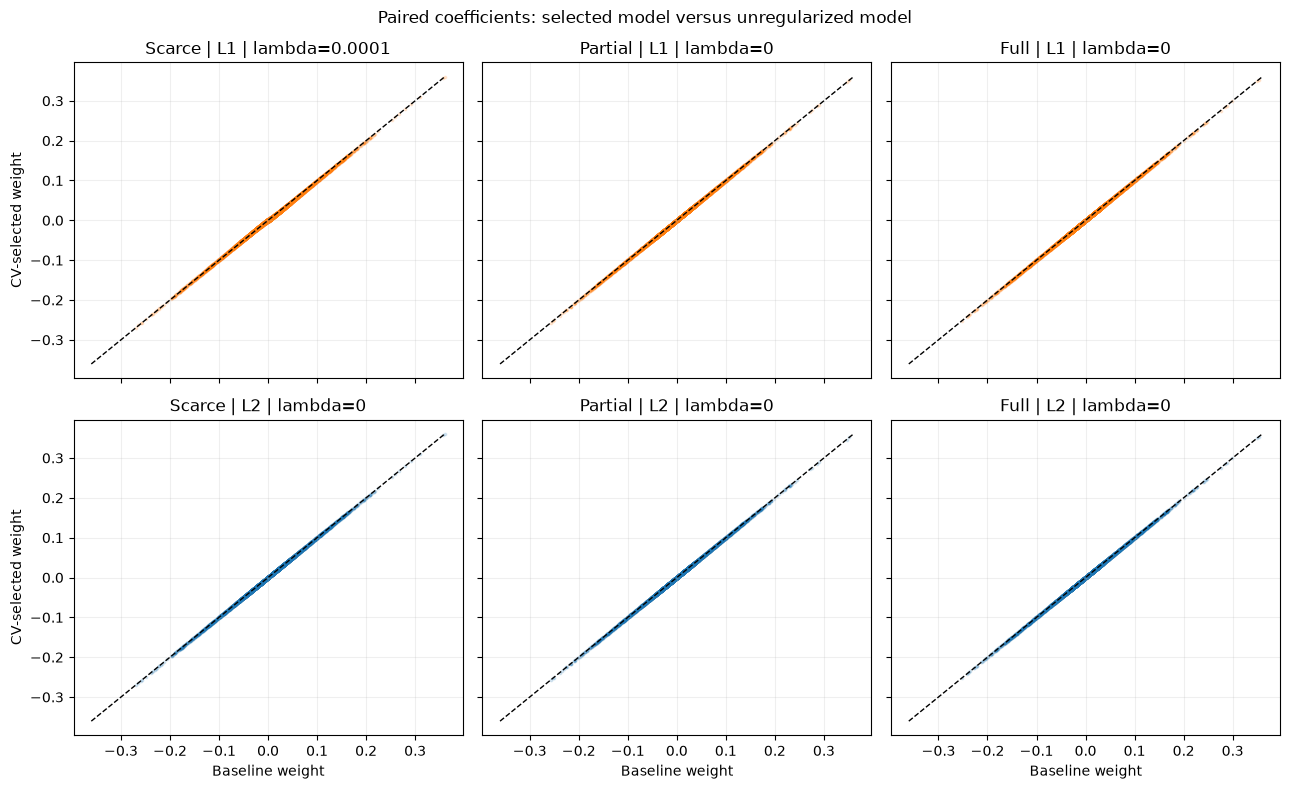

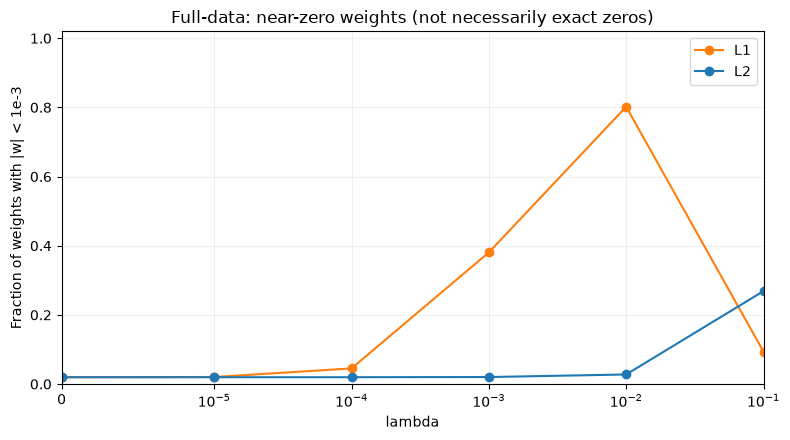

,regularizer,lambda,near_zero_fraction,exact_zero_fraction,mean_abs_weight,l2_norm
0,L1,0.00000,0.01977,0.0,0.03711,4.74146
1,L1,0.00001,0.02041,0.0,0.03695,4.73322
2,L1,0.00010,0.04515,0.0,0.03557,4.66083
3,L1,0.00100,0.38074,0.0,0.02451,4.10044
4,L1,0.01000,0.80191,0.0,0.00820,2.46914
5,L1,0.10000,0.09362,0.0,0.00509,0.52111
6,L2,0.00000,0.01977,0.0,0.03711,4.74146
7,L2,0.00001,0.01977,0.0,0.03710,4.74051
8,L2,0.00010,0.01977,0.0,0.03702,4.73198
9,L2,0.00100,0.02028,0.0,0.03624,4.64834


In [27]:
# Aligned boxplots instead of histograms.
model_order = ["Baseline", "L1", "L2"]
box_colors = ["lightgray", "moccasin", "lightblue"]

def draw_weight_boxplots(ax, arrays, labels):
    artists = ax.boxplot(arrays, tick_labels=labels, patch_artist=True, showfliers=True,
        flierprops={"marker": ".", "markersize": 2, "alpha": 0.25},
        medianprops={"color": "black"})
    for i, box in enumerate(artists["boxes"]):
        box.set_facecolor(box_colors[i % len(box_colors)])
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
    ax.grid(axis="y", alpha=0.2)

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for ax, (regime_name, models) in zip(axes, selected_models.items()):
    arrays = [models[name].linear.weight.detach().cpu().numpy().ravel() for name in model_order]
    draw_weight_boxplots(ax, arrays, model_order)
    ax.set_title(regime_name)
axes[0].set_ylabel("Weight value (all 10 x 784 coefficients)")
fig.suptitle("CV-selected weight distributions; whiskers = 1.5 IQR")
fig.tight_layout()
save_part3_figure(fig, "parte3_boxplots_selecionados.png")

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, (regularizer_name, models) in zip(axes, full_models_by_lambda.items()):
    arrays = [models[float(value)].linear.weight.detach().cpu().numpy().ravel() for value in lambda_grid]
    draw_weight_boxplots(ax, arrays, [f"{value:g}" for value in lambda_grid])
    for box in ax.patches:
        box.set_facecolor(colors[regularizer_name])
        box.set_alpha(0.5)
    ax.set_title(regularizer_name)
    ax.set_ylabel("Weight value")
axes[-1].set_xlabel("lambda")
fig.suptitle("Full-data: weight distributions over the lambda grid")
fig.tight_layout()
save_part3_figure(fig, "parte3_boxplots_grade_full.png")

# One figure per digit: Full-data models across the entire lambda grid.
# These are diagnostics only; lambda selection still uses corrupted-data CV.
for digit in range(10):
    digit_weights = {
        name: [models[float(value)].linear.weight[digit].detach().cpu().numpy()
               for value in lambda_grid]
        for name, models in full_models_by_lambda.items()
    }
    # One numerical color scale for both penalties and all lambdas in this figure.
    vmin = min(weights.min() for arrays in digit_weights.values() for weights in arrays)
    vmax = max(weights.max() for arrays in digit_weights.values() for weights in arrays)
    fig, axes = plt.subplots(len(regularizers), len(lambda_grid),
                             figsize=(14, 5.5), squeeze=False, constrained_layout=True)
    for row, regularizer_name in enumerate(regularizers):
        for col, lambda_value in enumerate(lambda_grid):
            ax = axes[row, col]
            im = plot_weight_image(ax, digit_weights[regularizer_name][col], vmin, vmax)
            label = f"lambda = {lambda_value:g}"
            if float(lambda_value) == selected_lambdas[("Full", regularizer_name)]:
                label += " (CV)"
            ax.set_title(label, fontsize=10)
            if col == 0:
                ax.set_ylabel(regularizer_name, fontsize=12)
    add_weight_colorbar(fig, axes, im)
    fig.suptitle(f"Full: digit {digit} — weights across lambda (0 = baseline; CV = selected)")
    save_part3_figure(fig, f"parte3_pesos_full_digito_{digit}.png")

# Keep a common extent for the paired-coefficient plots below.
weight_vmax = max(model.linear.weight.detach().abs().max().item()
                 for models in selected_models.values() for model in models.values())

# Paired coefficients: measured changes, not the slide's closed-form rule.
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
for col, (regime_name, models) in enumerate(selected_models.items()):
    original = models["Baseline"].linear.weight.detach().cpu().numpy().ravel()
    for row, regularizer_name in enumerate(regularizers):
        regularized = models[regularizer_name].linear.weight.detach().cpu().numpy().ravel()
        ax = axes[row, col]
        ax.scatter(original, regularized, s=3, alpha=0.15, color=colors[regularizer_name])
        ax.plot([-weight_vmax, weight_vmax], [-weight_vmax, weight_vmax], "k--", linewidth=1)
        ax.set_title(f"{regime_name} | {regularizer_name} | lambda={selected_lambdas[(regime_name, regularizer_name)]:g}")
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_ylabel("CV-selected weight")
        if row == 1:
            ax.set_xlabel("Baseline weight")
fig.suptitle("Paired coefficients: selected model versus unregularized model")
fig.tight_layout()
save_part3_figure(fig, "parte3_pesos_pareados.png")

fig, ax = plt.subplots(figsize=(8, 4.5))
for regularizer_name in regularizers:
    rows = full_weight_stats[full_weight_stats["regularizer"] == regularizer_name].sort_values("lambda")
    ax.plot(rows["lambda"], rows["near_zero_fraction"], "o-",
            color=colors[regularizer_name], label=regularizer_name)
ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlim(0, float(lambda_grid[-1]))
ax.set_xlabel("lambda")
ax.set_ylabel("Fraction of weights with |w| < 1e-3")
ax.set_ylim(0, 1.02)
ax.set_title("Full-data: near-zero weights (not necessarily exact zeros)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
save_part3_figure(fig, "parte3_esparsidade_full.png")
display(full_weight_stats.round(5))


### Análise adicional: convergência com 2.000 iterações

Este experimento estende o orçamento de 200 para **2.000 atualizações de SGD completo**.
Mantemos `lr=0.1`, três folds estratificados, semente 42, inicialização `42 + índice do fold`
e a mesma grade de λ para L1 e L2, nos três regimes. Os resultados anteriores ficam preservados.

- Treino e validação usam somente os dados de treinamento corrompidos. O pré-processamento é `/255`, fixo.
- A **iteração 0** registra a inicialização. Na linha da **iteração t**, todas as métricas
  se referem aos pesos **após t atualizações**, inclusive o gradiente calculado nesse estado.
- `train_ce` e `val_ce` são entropias cruzadas médias, **sem penalidade**.
  `train_objective = train_ce + regularization_term`. A penalidade usa a soma sobre os pesos;
  o bias não é penalizado. Acurácias são frações entre 0 e 1.
- Registramos também norma do gradiente, norma dos pesos, tamanho absoluto e relativo da atualização,
  fração de pesos próximos de zero e tempo acumulado por fold. L1 usa subgradiente de SGD;
  oscilações com passo fixo não devem ser confundidas com convergência ou zeros exatos.
- λ = 0 é treinado uma vez por fold como `Baseline`, e reutilizado para as análises L1 e L2.
  Os demais candidatos têm parâmetros independentes, embora sejam avaliados em conjunto por eficiência.
- Cada fold tem seu CSV e checkpoint, gravados a cada 50 iterações e ao finalizar. Após uma
  interrupção, retomamos do último checkpoint consistente (até 50 atualizações podem ser refeitas).
  Ao terminar, `iterations.csv` reúne todos os registros. Reexecutar as células reutiliza o cache.
- `config.json` registra hashes dos dados e da implementação de treinamento, versões, sementes,
  hiperparâmetros e convenções. `splits.csv` registra os índices de validação dentro de cada regime.
  Configurações diferentes recebem pastas diferentes; aumentar o orçamento estende o mesmo experimento.

As comparações usam os orçamentos fixos 200, 500, 1.000 e 2.000. Em cada orçamento, selecionamos
pela maior acurácia média de CV, com desempate pelo menor λ. **Não selecionamos a melhor iteração
observada**. A análise da janela final é descritiva: não declara convergência automaticamente nem
usa o teste para selecionar modelos. Estes diagnósticos não substituem os modelos finais da Parte 3.

In [28]:
from pathlib import Path
import sys
import importlib

convergence_root = Path.cwd()
if not (convergence_root / "convergencia.py").exists():
    convergence_root = convergence_root / "trab2"
if not (convergence_root / "convergencia.py").exists():
    raise FileNotFoundError("Execute a partir da pasta do repositório ou de trab2.")
if str(convergence_root.resolve()) not in sys.path:
    sys.path.insert(0, str(convergence_root.resolve()))
import convergencia
importlib.reload(convergencia)

conv_max_iter = 2000
conv_lambda_grid = [0.0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
conv_raw_datasets = {
    "Scarce": (X_scarce, y_scarce),
    "Partial": (X_partial, y_partial),
    "Full": (X_full, y_full),
}
conv_output_dir = convergence_root / "resultados_convergencia"

In [29]:
# First execution trains; subsequent executions load completed folds or resume.
conv_run_dir, conv_history = convergencia.run_experiment(
    conv_raw_datasets, conv_output_dir,
    max_iter=conv_max_iter, lambda_grid=conv_lambda_grid,
    lr=0.1, seed=seed, n_splits=3, checkpoint_every=50, num_threads=2,
)
print("Resultados:", conv_run_dir.resolve())
print("Registros por iteração:", len(conv_history))

Experiment a3b984a6b394fbf3: target=2000; directory=/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3
Scarce fold 1: cached through 2000
Scarce fold 2: cached through 2000
Scarce fold 3: cached through 2000
Partial fold 1: cached through 2000
Partial fold 2: cached through 2000
Partial fold 3: cached through 2000
Full fold 1: cached through 2000
Full fold 2: cached through 2000
Full fold 3: cached through 2000
Resultados: /home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3
Registros por iteração: 198099


In [30]:
# This analysis reads the cached metrics and does not train any models.
conv_history = convergencia.load_history(conv_run_dir)
conv_aggregate, conv_selection, conv_diagnostics = convergencia.summarize(
    conv_history, conv_run_dir,
    budgets=sorted({200, 500, 1000, 2000, conv_max_iter}), window=100,
)
print("Seleção por orçamento fixo; acurácias em fração; desvio amostral entre folds:")
display(conv_selection[[
    "regime", "regularizer", "iteration", "lambda", "train_accuracy_mean",
    "val_accuracy_mean", "val_accuracy_std", "train_val_gap",
]].sort_values(["regime", "regularizer", "iteration"]).round(6))

# Check the new run at 200 updates against the original experiment.
conv_original_path = convergence_root / "resultados_parte3" / "cv_results.csv"
if conv_original_path.exists():
    conv_reference = pd.read_csv(conv_original_path)
    conv_comparison_200 = conv_aggregate[conv_aggregate.iteration == 200].merge(
        conv_reference[["regime", "regularizer", "lambda", "cv_mean", "train_mean"]],
        on=["regime", "regularizer", "lambda"], validate="one_to_one",
    )
    conv_comparison_200["val_accuracy_difference"] = (
        conv_comparison_200.val_accuracy_mean - conv_comparison_200.cv_mean
    )
    conv_comparison_200["train_accuracy_difference"] = (
        conv_comparison_200.train_accuracy_mean - conv_comparison_200.train_mean
    )
    conv_comparison_200.to_csv(conv_run_dir / "comparison_200.csv", index=False, float_format="%.17g")
    print("Maior diferença absoluta de acurácia vs. execução original (200 atualizações):")
    display(conv_comparison_200[["val_accuracy_difference", "train_accuracy_difference"]].abs().max())
    # Batched matrix products can differ slightly in float32 rounding.
    if conv_comparison_200.val_accuracy_difference.abs().max() > 1e-6:
        print("Há diferenças: confira os folds, dados e arredondamento antes de atribuí-las ao orçamento.")

Seleção por orçamento fixo; acurácias em fração; desvio amostral entre folds:


,regime,regularizer,iteration,lambda,train_accuracy_mean,val_accuracy_mean,val_accuracy_std,train_val_gap
200,Full,L1,200,0.00000,0.858775,0.856933,0.002200,0.001842
2501,Full,L1,500,0.00001,0.874683,0.870500,0.003081,0.004183
3001,Full,L1,1000,0.00001,0.884017,0.877717,0.003770,0.006300
4001,Full,L1,2000,0.00001,0.890517,0.881867,0.002553,0.008650
12206,Full,L2,200,0.00000,0.858775,0.856933,0.002200,0.001842
12506,Full,L2,500,0.00000,0.874733,0.870450,0.003052,0.004283
13006,Full,L2,1000,0.00000,0.884017,0.877700,0.003789,0.006317
18008,Full,L2,2000,0.00010,0.890458,0.881800,0.002629,0.008658
24212,Partial,L1,200,0.00000,0.868950,0.855700,0.008007,0.013250
28514,Partial,L1,500,0.00010,0.889450,0.866300,0.005394,0.023150


Maior diferença absoluta de acurácia vs. execução original (200 atualizações):


val_accuracy_difference      0.0
train_accuracy_difference    0.0
dtype: float64

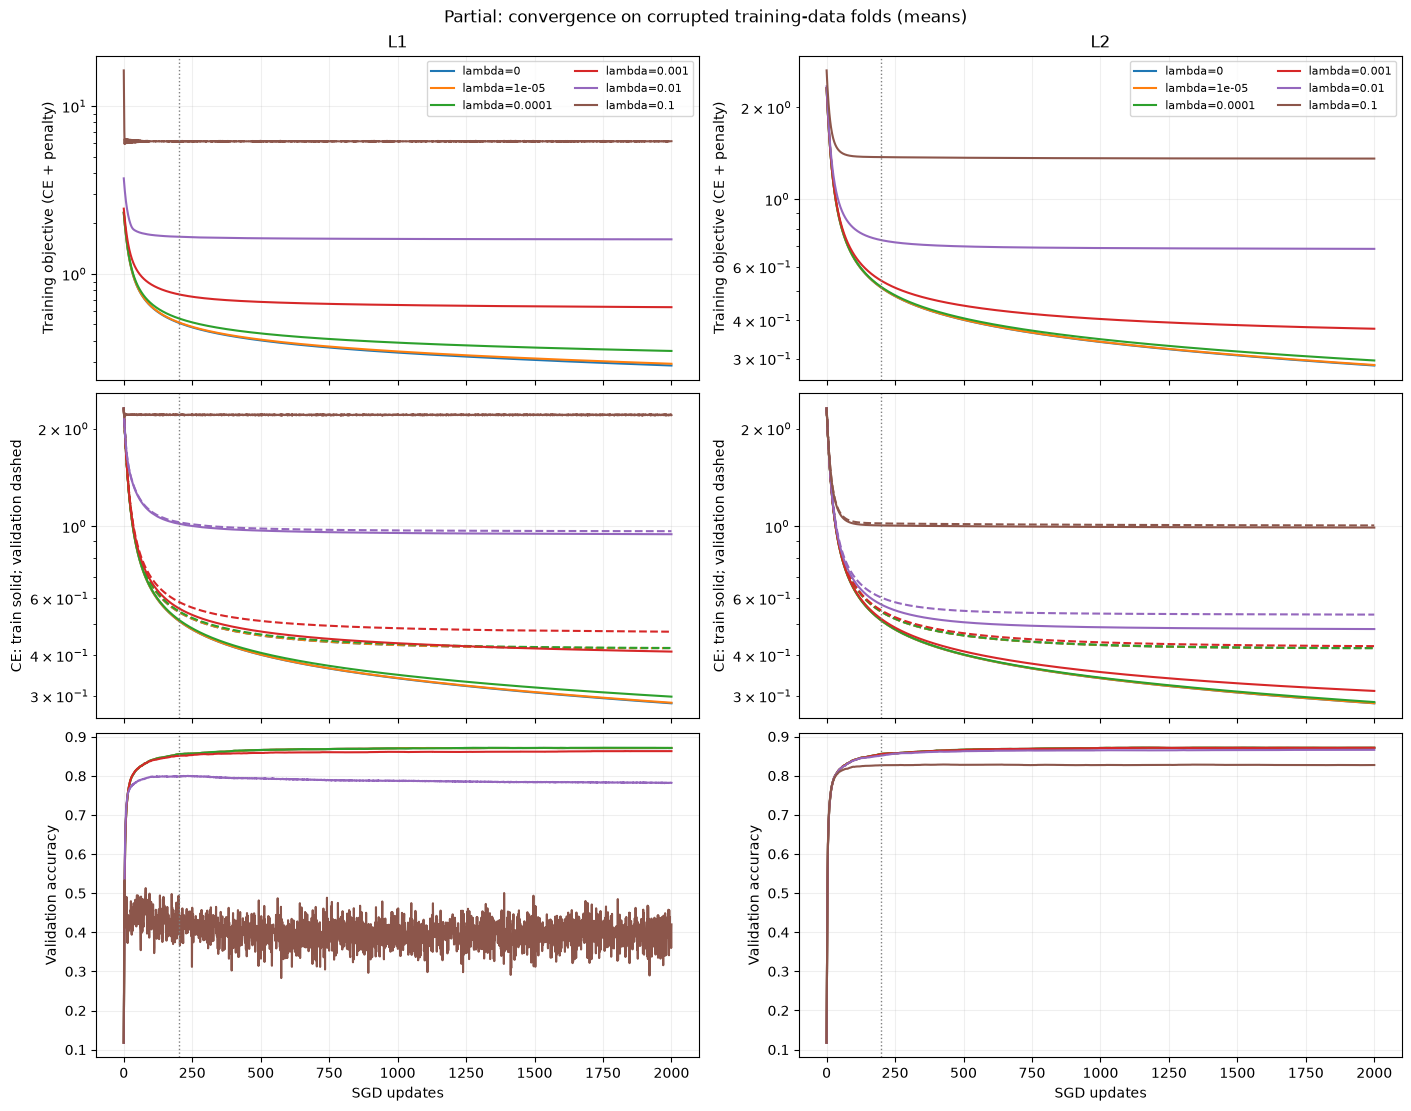

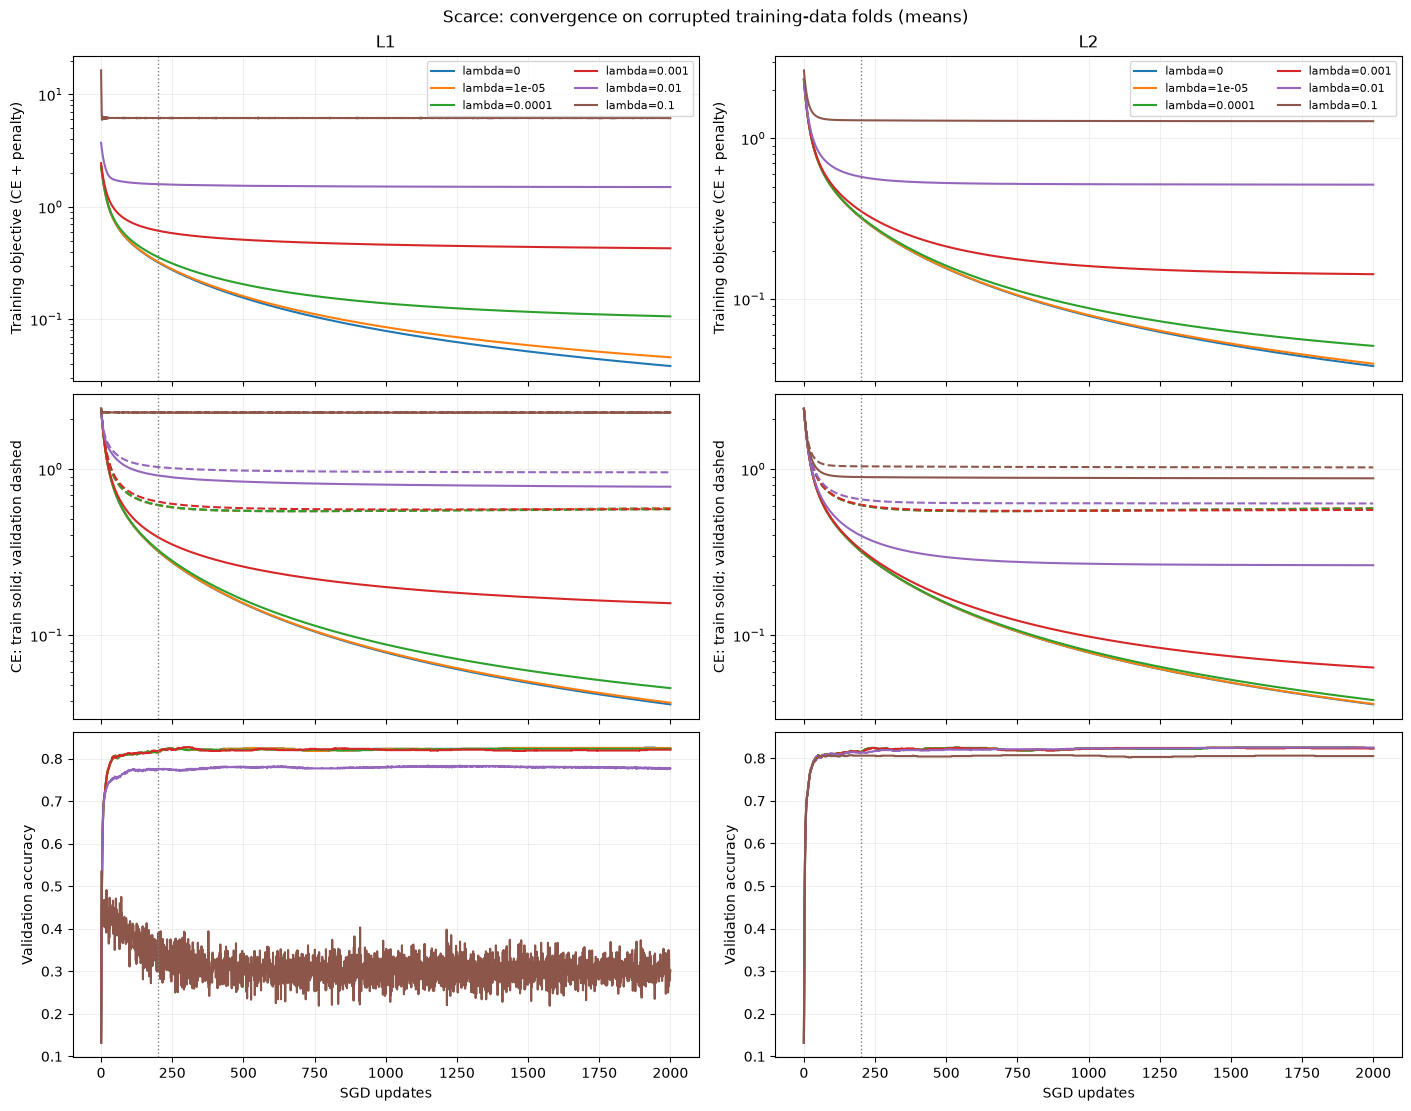

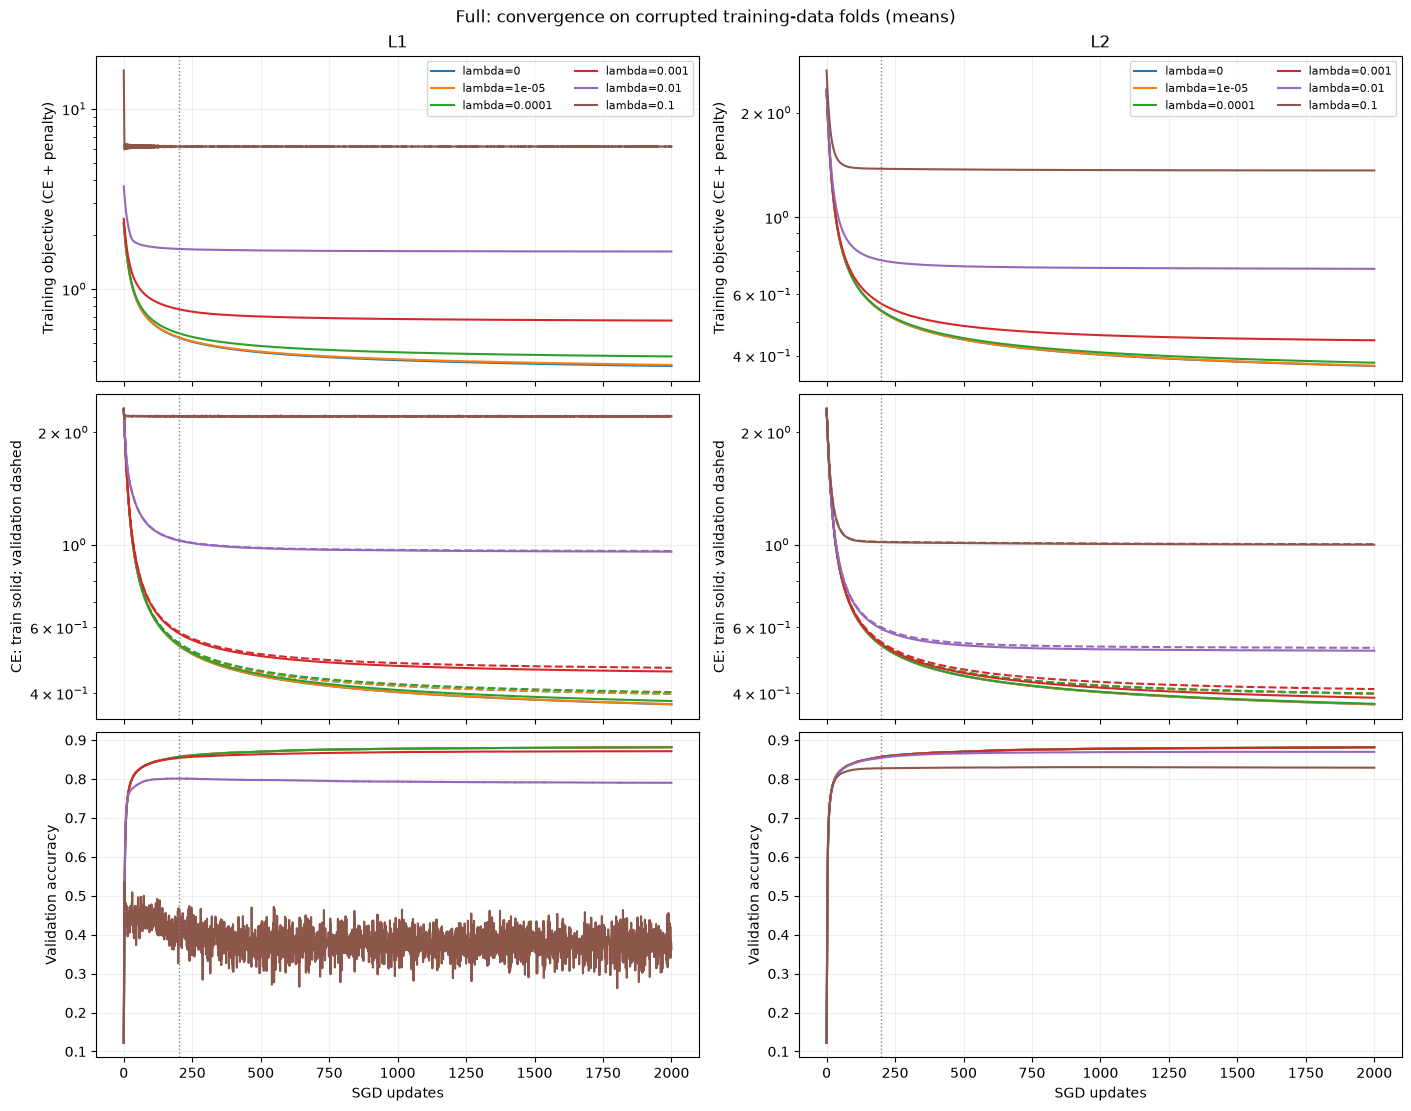

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [31]:
# One figure per regime: training objective, train/validation CE and validation accuracy.
# The dotted line marks the previous budget of 200 updates.
conv_figures = convergencia.plot_convergence(conv_aggregate, conv_run_dir)
for conv_fig in conv_figures:
    plt.figure(conv_fig.number)
    plt.show()

In [32]:
print("Diagnóstico por fold na janela das últimas 100 atualizações:")
display(conv_diagnostics.sort_values(["regime", "regularizer", "lambda", "fold"]).round(8))
print("Arquivos gravados:")
for conv_filename in [
    "config.json", "request.json", "status.json", "splits.csv", "iterations.csv",
    "cv_by_iteration.csv", "selected_by_budget.csv", "convergence_diagnostics.csv", "comparison_200.csv",
]:
    print(conv_run_dir / conv_filename)

Diagnóstico por fold na janela das últimas 100 atualizações:


,regime,regularizer,lambda,fold,last_iteration,window,objective_change,objective_relative_change,objective_tail_range,val_ce_change,val_accuracy_change,gradient_norm_last,relative_update_norm_last
0,Full,L1,0.00000,1,2000,100,-0.001819,-0.004812,0.001800,-0.001091,0.00045,0.013239,0.000156
1,Full,L1,0.00000,2,2000,100,-0.001844,-0.004904,0.001824,-0.001102,0.00020,0.013333,0.000157
2,Full,L1,0.00000,3,2000,100,-0.001868,-0.005030,0.001849,-0.000937,-0.00005,0.013417,0.000157
3,Full,L1,0.00001,1,2000,100,-0.001747,-0.004558,0.001729,-0.001098,0.00055,0.012971,0.000153
4,Full,L1,0.00001,2,2000,100,-0.001771,-0.004646,0.001753,-0.001112,0.00050,0.013064,0.000155
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,Scarce,L2,0.01000,2,2000,100,-0.000216,-0.000422,0.000214,-0.000169,0.00000,0.004597,0.000089
104,Scarce,L2,0.01000,3,2000,100,-0.000233,-0.000447,0.000231,-0.000137,0.00000,0.004769,0.000092
105,Scarce,L2,0.10000,1,2000,100,-0.000136,-0.000107,0.000134,-0.000230,0.00000,0.003528,0.000126
106,Scarce,L2,0.10000,2,2000,100,-0.000134,-0.000105,0.000133,-0.000338,0.00000,0.003511,0.000129


Arquivos gravados:
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/config.json
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/request.json
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/status.json
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/splits.csv
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/iterations.csv
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/cv_by_iteration.csv
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/selected_by_budget.csv
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/convergence_diagnostics.csv
/home/pedro/programas_etc/MC886/trab2/resultados_convergencia/a3b984a6b394fbf3/comparison_200.csv


**Conferência da execução registrada**

Os nove folds concluíram 2.000 atualizações, gerando 198.099 registros brutos.
Na comparação em 200 atualizações, 35 das 36 configurações coincidem com a
acurácia média de validação original até tolerância absoluta de `1e-6`.
A exceção é Full/L1/λ=0,1, com diferença de +0,035 ponto percentual.
A diferença está em `comparison_200.csv` e compara a **mesma iteração**;
portanto, não deve ser atribuída ao orçamento maior. Produtos matriciais conjuntos
em float32 podem alterar o arredondamento, e SGD com L1 e passo fixo pode ser
sensível a essas diferenças. Os resultados originais permanecem preservados.

**Roteiro para avaliar as curvas**

1. O objetivo de treino ainda diminui perto de 2.000 atualizações? Qual é sua variação
   absoluta e relativa nas últimas 100 atualizações? A curva oscila?
2. A perda de validação acompanha a perda de treino ou começa a aumentar?
   A acurácia estabilizada, isoladamente, é insuficiente para afirmar convergência.
3. A norma do gradiente e o tamanho relativo das atualizações diminuem? Para L1 com
   passo fixo, considere a possibilidade de oscilação perto de zero.
4. O λ selecionado muda entre 200, 500, 1.000 e 2.000 atualizações? Examine a média e
   o desvio entre folds, sem tratar esse desvio como intervalo de confiança.
5. Se o objetivo ainda variar, aumente `conv_max_iter` e execute novamente a célula de
   treinamento: o checkpoint permite continuar sem refazer as iterações já concluídas.

> **Questão 3**
>
> (a) À medida que $\lambda$ aumenta na regularização L2, como a acurácia de validação cruzada muda em cada regime de dados?
> Há valores ótimos claros ou a acurácia atinge um patamar? A diferença entre o melhor $\lambda$ e seus vizinhos é maior que o desvio padrão entre as partições?
>
> (b) Compare as imagens dos pesos do modelo L2 selecionado por validação cruzada, do modelo L1 selecionado por validação cruzada e do modelo de referência sem regularização. Quais diferenças você observa em termos de estrutura e esparsidade?
>
> (c) Relacione as imagens dos pesos à estrutura da corrupção identificada na Parte 1. O modelo selecionado por validação cruzada parece ter suprimido o padrão da corrupção, amplificado esse padrão ou isso é ambíguo quando se observam apenas os pesos?
>
> (d) **Preveja**, com base no que você observa nos pesos e nas curvas de validação cruzada, qual dos seus três modelos selecionados por validação cruzada (sem regularização / L2 / L1) você espera que tenha o melhor desempenho em imagens sem corrupção e qual terá o melhor desempenho em imagens com ruído impulsivo. Justifique sua previsão antes de ver qualquer resultado de teste.

**Questão 3 — decisão e análise**

Os regimes diferem só na quantidade de treino: **Scarce** 1.000, **Partial** 10.000, **Full** 60.000 imagens. Os três têm a mesma corrupção (traços artificiais); o ruído impulsivo é outra distribuição de teste.

Cada regime tem Baseline e modelos L1/L2 escolhidos por CV. Com $\lambda=0$, o modelo selecionado é idêntico ao Baseline daquele regime. Seleção: maior média de validação; empate → menor $\lambda$.

| Regime | $\lambda$ L1 | $\lambda$ L2 |
|--------|-------------|-------------|
| Scarce | $10^{-4}$ | $0$ |
| Partial | $0$ | $0$ |
| Full | $0$ | $0$ |

**(a)** Em L2, a acurácia de CV forma um **patamar** para $\lambda$ pequenos. As melhores médias estão em $\lambda=0$: ~**81,50%** (Scarce), **85,57%** (Partial) e **85,69%** (Full). As diferenças para vizinhos são menores que o desvio entre folds (~1,23 / 0,80 / 0,22 p.p.), então nenhum $\lambda>0$ é claramente superior. Com $\lambda=0{,}1$ a acurácia cai (~80,60% / 82,67% / 82,75%): L2 em excesso restringe os coeficientes e pode subajustar.

**(b)** Em Partial e Full, L1 e L2 escolheram $\lambda=0$: idênticos ao Baseline (mesmos pesos/esparsidade). No Scarce, L2 também é $\lambda=0$; L1 com $10^{-4}$ muda pouco e preserva a estrutura dos mapas (pontos perto da diagonal no gráfico pareado). Na grade completa, L1 forte concentra pesos perto de zero e L2 encolhe magnitudes de forma mais uniforme — mas esses candidatos **não** foram selecionados. Pesos “quase zero” ≠ zeros exatos (SGD com subgradiente e passo fixo).

**(c)** Na Parte 1, a corrupção são traços com posição/orientação variáveis. Os mapas de pesos mostram estrutura de dígitos, mas traços úteis e de corrupção podem ocupar regiões parecidas, então **não** dá para dizer com segurança quais coeficientes respondem à corrupção. Como os selecionados são iguais ou quase iguais ao Baseline, não há evidência visual clara de supressão ou amplificação. Conclusão **ambígua** só olhando pesos. A CV treina e valida em dados corrompidos e não isola o efeito em relação ao clean.

**(d) Previsão (antes do teste):** em Partial e Full, os três modelos devem ter o **mesmo** desempenho em clean e em impulse, pois são idênticos ao Baseline (dentro de cada regime). No Scarce, L2 = Baseline; L1 ganha só ~0,20 p.p. na validação corrompida, abaixo do desvio entre folds (~1,29 p.p.), então esperamos desempenho **semelhante**, sem vencedor claro em clean nem em impulse. Vantagem pequena na validação corrompida **não** garante vantagem fora dessa distribuição.

---

## Parte 4. Teste

**(2,0 pontos)**

Até agora, todas as decisões, a análise do tamanho do conjunto de dados e a seleção da regularização foram feitas utilizando apenas os dados de treinamento corrompidos e a validação cruzada.
**Agora usamos os conjuntos de teste** para avaliar os modelos que você selecionou.

1. Avalie todos os modelos escolhidos (modelo de referência, L2 e L1 selecionados por validação cruzada, para cada regime de dados) nas três versões do conjunto de teste.
2. Usando os modelos do regime de dados completos armazenados para cada $\lambda$, trace as **curvas de compromisso (trade-off)**: acurácia em `test_corrupted` versus acurácia em `test_clean` e versus acurácia em `test_impulse`, com uma curva por regularizador, destacando os modelos selecionados por validação cruzada.
3. Trace a **esparsidade** (fração de pesos com $|w| < 10^{-3}$) dos modelos L1 e L2 em função de $\lambda$.
4. Calcule a **acurácia por classe** em cada versão do conjunto de teste para os modelos selecionados por validação cruzada e identifique quais dígitos são mais prejudicados por cada corrupção.

In [33]:
# ============================================================
# Parte 4.1 — Avaliar modelos escolhidos nos três conjuntos de teste
# ============================================================
# test_images  -> test_corrupted (mesma corrupção do treino)
# clean_images -> test_clean
# impulse_images -> test_impulse

from pathlib import Path

parte4_dir = Path("resultados_parte4")
parte4_dir.mkdir(exist_ok=True)

# --- Carregar testes ---
y_test = np.load(f"{DATA_DIR}/test/test_labels.npy")
test_sets = {
    "test_corrupted": np.load(f"{DATA_DIR}/test/test_images.npy"),
    "test_clean": np.load(f"{DATA_DIR}/test/clean_images.npy"),
    "test_impulse": np.load(f"{DATA_DIR}/test/impulse_images.npy"),
}
test_tensors = {
    name: torch.from_numpy(preprocess_images(X))
    for name, X in test_sets.items()
}
y_test_t = torch.as_tensor(y_test, dtype=torch.long)

print("Conjuntos de teste:")
for name, X in test_sets.items():
    print(f"  {name:<15} shape={X.shape}  dtype={X.dtype}")
print(f"  labels          shape={y_test.shape}  classes={np.unique(y_test).tolist()}")

# --- Modelos escolhidos: memória (se a Parte 3 rodou nesta sessão) ou disco ---
def load_selected_models_from_disk(path="resultados_parte3/modelos_parte3.pt"):
    bundle = torch.load(path, map_location="cpu", weights_only=False)
    models = {}
    for regime, state_dicts in bundle["selected_state_dicts"].items():
        models[regime] = {}
        for name, state_dict in state_dicts.items():
            model = LinearModel()
            model.load_state_dict(state_dict)
            model.eval()
            models[regime][name] = model
    lambdas = bundle["selected_lambdas"]
    # torch pode serializar chaves-tupla; normaliza para (str, str)
    if lambdas and not isinstance(next(iter(lambdas.keys())), tuple):
        lambdas = {(k[0], k[1]): float(v) for k, v in lambdas.items()}
    else:
        lambdas = {(str(r), str(reg)): float(lam) for (r, reg), lam in lambdas.items()}
    return models, lambdas

if "selected_models" in globals() and selected_models:
    models_to_eval = selected_models
    lambdas_to_report = selected_lambdas
    print("\nUsando selected_models da sessão atual.")
else:
    models_to_eval, lambdas_to_report = load_selected_models_from_disk()
    print("\nCarregados de resultados_parte3/modelos_parte3.pt")

model_order = ["Baseline", "L1", "L2"]
test_order = ["test_corrupted", "test_clean", "test_impulse"]

# --- Avaliar ---
rows = []
for regime_name, models in models_to_eval.items():
    for model_name in model_order:
        model = models[model_name]
        model.eval()
        if model_name == "Baseline":
            lam = 0.0
        else:
            lam = float(lambdas_to_report[(regime_name, model_name)])
        with torch.no_grad():
            accs = {
                test_name: accuracy(model(X_t), y_test_t)
                for test_name, X_t in test_tensors.items()
            }
        rows.append({
            "regime": regime_name,
            "model": model_name,
            "lambda": lam,
            **accs,
        })

test_results = pd.DataFrame(rows)
test_results = test_results.sort_values(
    ["regime", "model"],
    key=lambda s: s.map(
        {"Scarce": 0, "Partial": 1, "Full": 2,
         "Baseline": 0, "L1": 1, "L2": 2}
    ).fillna(99),
).reset_index(drop=True)

test_results.to_csv(parte4_dir / "test_results_selected.csv", index=False)

print("\nAcurácia dos modelos escolhidos (fração):")
display(test_results.round(5))

print("Resumo por regime (acurácia):")
for regime_name in ["Scarce", "Partial", "Full"]:
    block = test_results[test_results["regime"] == regime_name]
    print(f"\n=== {regime_name} ===")
    for _, row in block.iterrows():
        print(
            f"  {row['model']:<8} λ={row['lambda']:<8g} | "
            f"corrupted={row['test_corrupted']:.4f} | "
            f"clean={row['test_clean']:.4f} | "
            f"impulse={row['test_impulse']:.4f}"
        )

Conjuntos de teste:
  test_corrupted  shape=(10000, 28, 28, 1)  dtype=uint8
  test_clean      shape=(10000, 28, 28, 1)  dtype=uint8
  test_impulse    shape=(10000, 28, 28, 1)  dtype=uint8
  labels          shape=(10000,)  classes=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Usando selected_models da sessão atual.

Acurácia dos modelos escolhidos (fração):


,regime,model,lambda,test_corrupted,test_clean,test_impulse
0,Scarce,Baseline,0.0000,0.8506,0.8657,0.8514
1,Scarce,L1,0.0001,0.8503,0.8653,0.8518
2,Scarce,L2,0.0000,0.8506,0.8657,0.8514
3,Partial,Baseline,0.0000,0.8667,0.8818,0.8692
4,Partial,L1,0.0000,0.8667,0.8818,0.8692
5,Partial,L2,0.0000,0.8667,0.8818,0.8692
6,Full,Baseline,0.0000,0.8663,0.8803,0.8716
7,Full,L1,0.0000,0.8663,0.8803,0.8716
8,Full,L2,0.0000,0.8663,0.8803,0.8716


Resumo por regime (acurácia):

=== Scarce ===
  Baseline λ=0        | corrupted=0.8506 | clean=0.8657 | impulse=0.8514
  L1       λ=0.0001   | corrupted=0.8503 | clean=0.8653 | impulse=0.8518
  L2       λ=0        | corrupted=0.8506 | clean=0.8657 | impulse=0.8514

=== Partial ===
  Baseline λ=0        | corrupted=0.8667 | clean=0.8818 | impulse=0.8692
  L1       λ=0        | corrupted=0.8667 | clean=0.8818 | impulse=0.8692
  L2       λ=0        | corrupted=0.8667 | clean=0.8818 | impulse=0.8692

=== Full ===
  Baseline λ=0        | corrupted=0.8663 | clean=0.8803 | impulse=0.8716
  L1       λ=0        | corrupted=0.8663 | clean=0.8803 | impulse=0.8716
  L2       λ=0        | corrupted=0.8663 | clean=0.8803 | impulse=0.8716


Acurácias Full-data ao longo da grade de λ:


,regularizer,lambda,selected,test_corrupted,test_clean,test_impulse
0,L1,0.00000,True,0.8663,0.8803,0.8716
1,L1,0.00001,False,0.8663,0.8803,0.8716
2,L1,0.00010,False,0.8655,0.8802,0.8718
3,L1,0.00100,False,0.8624,0.8766,0.8688
4,L1,0.01000,False,0.8083,0.8211,0.8142
5,L1,0.10000,False,0.4061,0.4368,0.3626
6,L2,0.00000,True,0.8663,0.8803,0.8716
7,L2,0.00001,False,0.8663,0.8803,0.8716
8,L2,0.00010,False,0.8663,0.8802,0.8716
9,L2,0.00100,False,0.8660,0.8800,0.8717


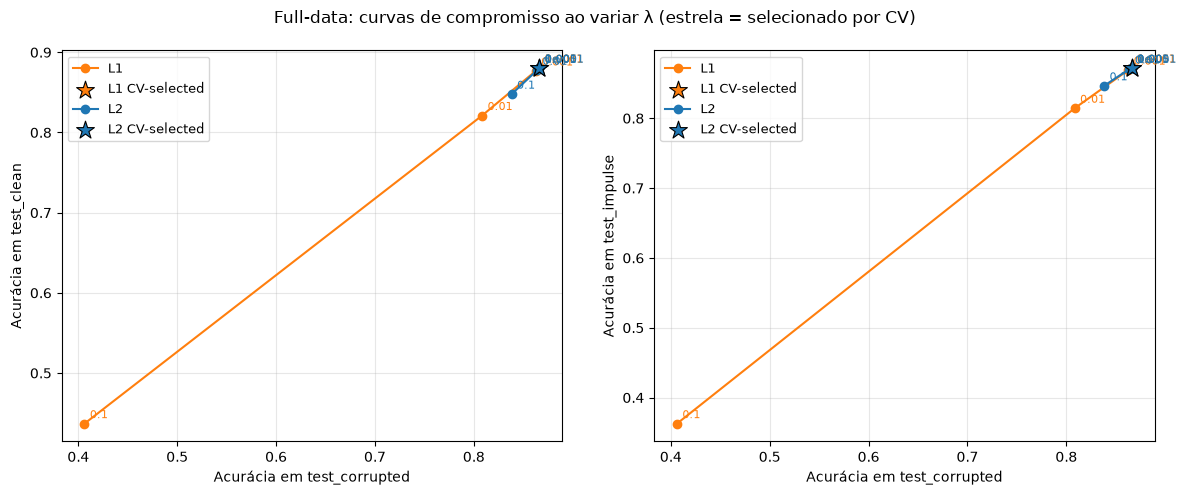

λ selecionados no Full: {'L1': 0.0, 'L2': 0.0}


In [34]:
# ============================================================
# Parte 4.2 — Curvas de compromisso (Full-data × λ)
# ============================================================
# Eixo x: acurácia em test_corrupted
# Eixo y: acurácia em test_clean (esquerda) ou test_impulse (direita)
# Uma curva por regularizador; estrela = λ escolhido por CV no Full.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

try:
    from IPython.display import display
except ImportError:
    display = print

DATA_DIR = globals().get("DATA_DIR", "data_2s2026")
parte4_dir = Path("resultados_parte4")
parte4_dir.mkdir(exist_ok=True)
figures_dir = Path("imagens_respostas")
figures_dir.mkdir(exist_ok=True)


class LinearModel(nn.Module):
    def __init__(self, n_features: int = 784, n_classes: int = 10):
        super().__init__()
        self.linear = nn.Linear(n_features, n_classes)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.linear(X)


def preprocess_images(X: np.ndarray) -> np.ndarray:
    X = np.asarray(X, dtype=np.float32).reshape(len(X), -1)
    return X / 255.0


def accuracy(logits: torch.Tensor, y: torch.Tensor) -> float:
    return (logits.argmax(dim=-1) == y).float().mean().item()


# Reusa tensores da 4.1 se existirem; senão carrega de novo.
if "test_tensors" not in globals() or "y_test_t" not in globals():
    y_test = np.load(f"{DATA_DIR}/test/test_labels.npy")
    test_tensors = {
        "test_corrupted": torch.from_numpy(
            preprocess_images(np.load(f"{DATA_DIR}/test/test_images.npy"))
        ),
        "test_clean": torch.from_numpy(
            preprocess_images(np.load(f"{DATA_DIR}/test/clean_images.npy"))
        ),
        "test_impulse": torch.from_numpy(
            preprocess_images(np.load(f"{DATA_DIR}/test/impulse_images.npy"))
        ),
    }
    y_test_t = torch.as_tensor(y_test, dtype=torch.long)

bundle = torch.load(
    "resultados_parte3/modelos_parte3.pt", map_location="cpu", weights_only=False
)
lambda_grid = [float(v) for v in bundle["config"]["lambda_grid"]]
selected_lambdas = {
    (str(r), str(reg)): float(lam)
    for (r, reg), lam in bundle["selected_lambdas"].items()
}
colors = {"L1": "tab:orange", "L2": "tab:blue"}

# Avalia todos os modelos Full × λ nos três testes
tradeoff_rows = []
for regularizer_name, state_by_lambda in bundle["full_state_dicts"].items():
    state_by_lambda = {float(k): v for k, v in state_by_lambda.items()}
    for lambda_value in lambda_grid:
        model = LinearModel()
        model.load_state_dict(state_by_lambda[float(lambda_value)])
        model.eval()
        with torch.no_grad():
            accs = {
                name: accuracy(model(X_t), y_test_t)
                for name, X_t in test_tensors.items()
            }
        tradeoff_rows.append({
            "regularizer": regularizer_name,
            "lambda": float(lambda_value),
            "selected": float(lambda_value) == selected_lambdas[("Full", regularizer_name)],
            **accs,
        })

tradeoff_results = pd.DataFrame(tradeoff_rows).sort_values(
    ["regularizer", "lambda"]
).reset_index(drop=True)
tradeoff_results.to_csv(parte4_dir / "tradeoff_full_by_lambda.csv", index=False)

print("Acurácias Full-data ao longo da grade de λ:")
display(tradeoff_results.round(5))

# Curvas de compromisso
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
y_targets = [
    ("test_clean", "Acurácia em test_clean"),
    ("test_impulse", "Acurácia em test_impulse"),
]

for ax, (y_name, y_label) in zip(axes, y_targets):
    for regularizer_name in ["L1", "L2"]:
        block = tradeoff_results[
            tradeoff_results["regularizer"] == regularizer_name
        ].sort_values("lambda")
        ax.plot(
            block["test_corrupted"],
            block[y_name],
            "o-",
            color=colors[regularizer_name],
            label=regularizer_name,
            markersize=6,
        )
        # anota cada λ perto do ponto
        for _, row in block.iterrows():
            ax.annotate(
                f"{row['lambda']:g}",
                (row["test_corrupted"], row[y_name]),
                textcoords="offset points",
                xytext=(4, 4),
                fontsize=8,
                color=colors[regularizer_name],
            )
        # destaca o escolhido por CV
        chosen = block[block["selected"]]
        if len(chosen):
            ax.scatter(
                chosen["test_corrupted"],
                chosen[y_name],
                s=180,
                marker="*",
                color=colors[regularizer_name],
                edgecolors="black",
                linewidths=0.8,
                zorder=5,
                label=f"{regularizer_name} CV-selected",
            )
    ax.set_xlabel("Acurácia em test_corrupted")
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.3)
    ax.legend(loc="best", fontsize=9)

fig.suptitle(
    "Full-data: curvas de compromisso ao variar λ (estrela = selecionado por CV)"
)
fig.tight_layout()
fig.savefig(figures_dir / "parte4_tradeoff_full.png", dpi=130, bbox_inches="tight")
plt.show()

print(
    "λ selecionados no Full:",
    {reg: selected_lambdas[("Full", reg)] for reg in ("L1", "L2")},
)

Esparsidade = fração de |w| < 0.001


,regularizer,lambda,near_zero_fraction,exact_zero_fraction,mean_abs_weight,selected
0,L1,0.00000,0.01977,0.0,0.03711,True
1,L1,0.00001,0.02041,0.0,0.03695,False
2,L1,0.00010,0.04515,0.0,0.03557,False
3,L1,0.00100,0.38074,0.0,0.02451,False
4,L1,0.01000,0.80191,0.0,0.00820,False
5,L1,0.10000,0.09362,0.0,0.00509,False
6,L2,0.00000,0.01977,0.0,0.03711,True
7,L2,0.00001,0.01977,0.0,0.03710,False
8,L2,0.00010,0.01977,0.0,0.03702,False
9,L2,0.00100,0.02028,0.0,0.03624,False


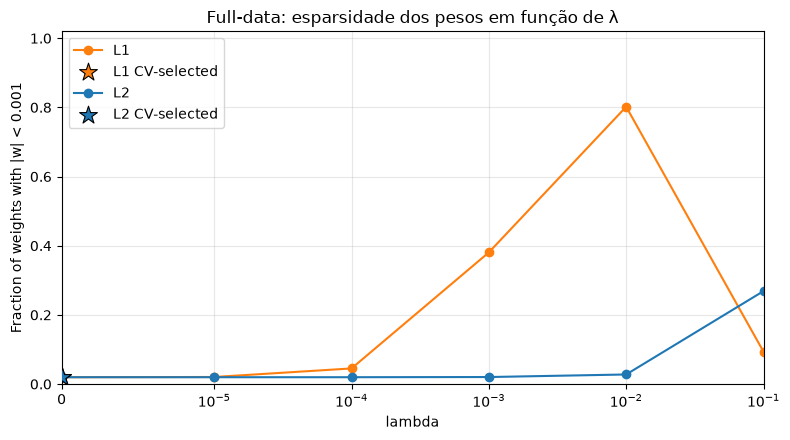

λ selecionados no Full: {'L1': 0.0, 'L2': 0.0}


In [35]:
# ============================================================
# Parte 4.3 — Esparsidade dos pesos Full-data em função de λ
# ============================================================
# Esparsidade := fração de pesos com |w| < 1e-3
# (próximos de zero; SGD+L1 com passo fixo não garante zeros exatos)

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

try:
    from IPython.display import display
except ImportError:
    display = print

parte4_dir = Path("resultados_parte4")
parte4_dir.mkdir(exist_ok=True)
figures_dir = Path("imagens_respostas")
figures_dir.mkdir(exist_ok=True)

NEAR_ZERO = 1e-3
colors = {"L1": "tab:orange", "L2": "tab:blue"}

bundle = torch.load(
    "resultados_parte3/modelos_parte3.pt", map_location="cpu", weights_only=False
)
lambda_grid = [float(v) for v in bundle["config"]["lambda_grid"]]
selected_lambdas = {
    (str(r), str(reg)): float(lam)
    for (r, reg), lam in bundle["selected_lambdas"].items()
}

sparsity_rows = []
for regularizer_name, state_by_lambda in bundle["full_state_dicts"].items():
    state_by_lambda = {float(k): v for k, v in state_by_lambda.items()}
    for lambda_value in lambda_grid:
        weights = state_by_lambda[float(lambda_value)]["linear.weight"].detach()
        flat = weights.reshape(-1)
        near_zero_fraction = (flat.abs() < NEAR_ZERO).float().mean().item()
        exact_zero_fraction = (flat == 0).float().mean().item()
        sparsity_rows.append({
            "regularizer": regularizer_name,
            "lambda": float(lambda_value),
            "near_zero_fraction": near_zero_fraction,
            "exact_zero_fraction": exact_zero_fraction,
            "mean_abs_weight": flat.abs().mean().item(),
            "selected": float(lambda_value) == selected_lambdas[("Full", regularizer_name)],
        })

sparsity_results = pd.DataFrame(sparsity_rows).sort_values(
    ["regularizer", "lambda"]
).reset_index(drop=True)
sparsity_results.to_csv(parte4_dir / "sparsity_full_by_lambda.csv", index=False)

print(f"Esparsidade = fração de |w| < {NEAR_ZERO:g}")
display(sparsity_results.round(5))

fig, ax = plt.subplots(figsize=(8, 4.5))
for regularizer_name in ["L1", "L2"]:
    block = sparsity_results[
        sparsity_results["regularizer"] == regularizer_name
    ].sort_values("lambda")
    ax.plot(
        block["lambda"],
        block["near_zero_fraction"],
        "o-",
        color=colors[regularizer_name],
        label=regularizer_name,
    )
    chosen = block[block["selected"]]
    if len(chosen):
        ax.scatter(
            chosen["lambda"],
            chosen["near_zero_fraction"],
            s=180,
            marker="*",
            color=colors[regularizer_name],
            edgecolors="black",
            linewidths=0.8,
            zorder=5,
            label=f"{regularizer_name} CV-selected",
        )

ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlim(0, float(lambda_grid[-1]))
ax.set_ylim(0, 1.02)
ax.set_xlabel("lambda")
ax.set_ylabel(f"Fraction of weights with |w| < {NEAR_ZERO:g}")
ax.set_title("Full-data: esparsidade dos pesos em função de λ")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(figures_dir / "parte4_esparsidade_full.png", dpi=130, bbox_inches="tight")
plt.show()

print(
    "λ selecionados no Full:",
    {reg: selected_lambdas[("Full", reg)] for reg in ("L1", "L2")},
)

Amostra (Full × Baseline) — acurácia por dígito:


test,test_corrupted,test_clean,test_impulse
digit,,,
0,0.9541,0.9694,0.9520
1,0.9559,0.9753,0.9445
2,0.8072,0.8178,0.8382
3,0.8475,0.8703,0.8505
4,0.8798,0.9012,0.8890
5,0.7455,0.7478,0.8083
6,0.9144,0.9280,0.9061
7,0.8638,0.8706,0.8813
8,0.8296,0.8347,0.8152



Prejuízo médio (clean − teste), média sobre regimes × modelos:


,digit,harm_corrupted,harm_impulse,acc_clean,acc_corrupted,acc_impulse
0,0,0.0130,0.0160,0.9671,0.9541,0.9511
1,1,0.0191,0.0300,0.9771,0.9580,0.9471
2,2,0.0090,-0.0181,0.8106,0.8016,0.8287
3,3,0.0279,0.0187,0.8611,0.8331,0.8424
4,4,0.0269,0.0199,0.8981,0.8711,0.8781
5,5,-0.0012,-0.0566,0.7534,0.7546,0.8099
6,6,0.0090,0.0223,0.9252,0.9161,0.9029
7,7,0.0120,0.0008,0.8690,0.8570,0.8682
8,8,0.0081,0.0243,0.8160,0.8079,0.7917
9,9,0.0208,0.0525,0.8598,0.8390,0.8073


Mais prejudicados pela corrupção de treino (vs clean): [3, 4, 9] | harm = [0.0279, 0.0269, 0.0208]
Mais prejudicados pelo ruído impulsivo (vs clean): [9, 1, 8] | harm = [0.0525, 0.03, 0.0243]


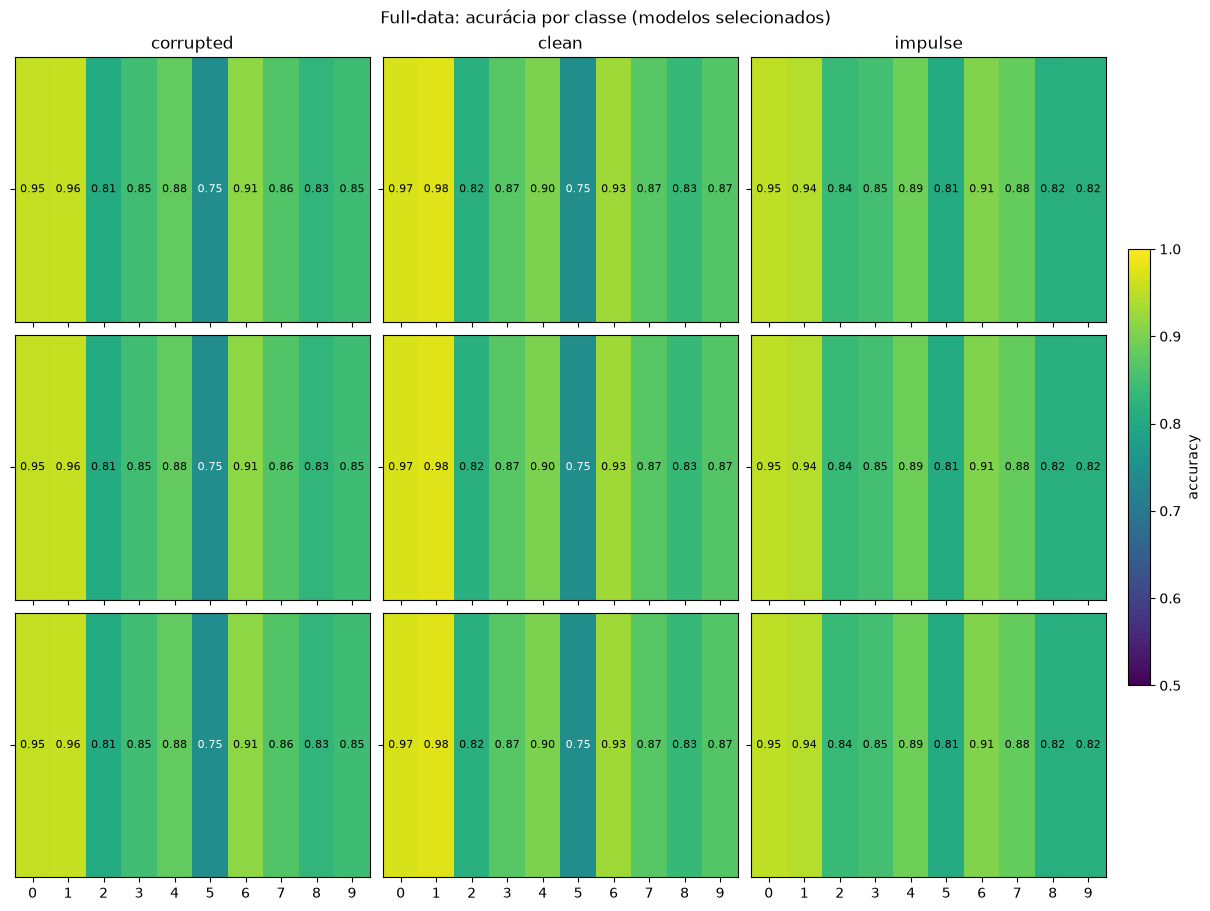

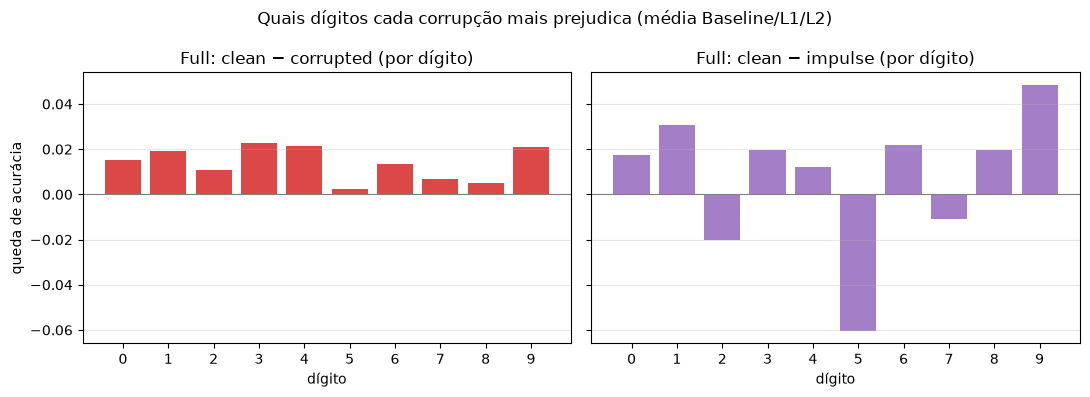

In [36]:
# ============================================================
# Parte 4.4 — Acurácia por classe nos três testes
# ============================================================
# Para cada modelo escolhido por CV (Baseline / L1 / L2 × regime):
#   acurácia por dígito 0–9 em test_corrupted, test_clean, test_impulse.
# Prejuízo da corrupção ≈ acurácia_clean − acurácia_no_teste_corrompido.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

try:
    from IPython.display import display
except ImportError:
    display = print

DATA_DIR = globals().get("DATA_DIR", "data_2s2026")
parte4_dir = Path("resultados_parte4")
parte4_dir.mkdir(exist_ok=True)
figures_dir = Path("imagens_respostas")
figures_dir.mkdir(exist_ok=True)


class LinearModel(nn.Module):
    def __init__(self, n_features: int = 784, n_classes: int = 10):
        super().__init__()
        self.linear = nn.Linear(n_features, n_classes)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.linear(X)


def preprocess_images(X: np.ndarray) -> np.ndarray:
    X = np.asarray(X, dtype=np.float32).reshape(len(X), -1)
    return X / 255.0


def per_class_accuracy(logits: torch.Tensor, y: torch.Tensor, n_classes: int = 10):
    """Acurácia por classe: acertos na classe k / nº de exemplos da classe k."""
    pred = logits.argmax(dim=-1)
    y_np = y.detach().cpu().numpy()
    pred_np = pred.detach().cpu().numpy()
    out = {}
    for k in range(n_classes):
        mask = y_np == k
        out[k] = float((pred_np[mask] == k).mean()) if mask.any() else float("nan")
    return out


# --- Dados de teste ---
if "test_tensors" not in globals() or "y_test_t" not in globals():
    y_test = np.load(f"{DATA_DIR}/test/test_labels.npy")
    test_tensors = {
        "test_corrupted": torch.from_numpy(
            preprocess_images(np.load(f"{DATA_DIR}/test/test_images.npy"))
        ),
        "test_clean": torch.from_numpy(
            preprocess_images(np.load(f"{DATA_DIR}/test/clean_images.npy"))
        ),
        "test_impulse": torch.from_numpy(
            preprocess_images(np.load(f"{DATA_DIR}/test/impulse_images.npy"))
        ),
    }
    y_test_t = torch.as_tensor(y_test, dtype=torch.long)
else:
    y_test = y_test_t.detach().cpu().numpy()

# --- Modelos selecionados ---
bundle = torch.load(
    "resultados_parte3/modelos_parte3.pt", map_location="cpu", weights_only=False
)
selected_lambdas = {
    (str(r), str(reg)): float(lam)
    for (r, reg), lam in bundle["selected_lambdas"].items()
}
model_order = ["Baseline", "L1", "L2"]
test_order = ["test_corrupted", "test_clean", "test_impulse"]

rows = []
for regime_name, state_dicts in bundle["selected_state_dicts"].items():
    for model_name in model_order:
        model = LinearModel()
        model.load_state_dict(state_dicts[model_name])
        model.eval()
        lam = (
            0.0
            if model_name == "Baseline"
            else float(selected_lambdas[(regime_name, model_name)])
        )
        with torch.no_grad():
            for test_name, X_t in test_tensors.items():
                class_acc = per_class_accuracy(model(X_t), y_test_t)
                for digit, acc in class_acc.items():
                    rows.append({
                        "regime": regime_name,
                        "model": model_name,
                        "lambda": lam,
                        "test": test_name,
                        "digit": digit,
                        "accuracy": acc,
                        "n_examples": int((y_test == digit).sum()),
                    })

per_class = pd.DataFrame(rows)
per_class.to_csv(parte4_dir / "per_class_accuracy.csv", index=False)

# Tabela larga: uma coluna por teste (média sobre regimes/modelos é feita nos gráficos)
print("Amostra (Full × Baseline) — acurácia por dígito:")
sample = per_class[
    (per_class["regime"] == "Full") & (per_class["model"] == "Baseline")
].pivot(index="digit", columns="test", values="accuracy")[test_order]
display(sample.round(4))

# Prejuízo relativo ao clean: clean − corrupted e clean − impulse
harm_rows = []
for (regime, model), block in per_class.groupby(["regime", "model"]):
    wide = block.pivot(index="digit", columns="test", values="accuracy")
    for digit in range(10):
        clean = wide.loc[digit, "test_clean"]
        harm_rows.append({
            "regime": regime,
            "model": model,
            "digit": digit,
            "acc_clean": clean,
            "acc_corrupted": wide.loc[digit, "test_corrupted"],
            "acc_impulse": wide.loc[digit, "test_impulse"],
            "harm_corrupted": clean - wide.loc[digit, "test_corrupted"],
            "harm_impulse": clean - wide.loc[digit, "test_impulse"],
        })
harm = pd.DataFrame(harm_rows)
harm.to_csv(parte4_dir / "per_class_harm.csv", index=False)

# Resumo: dígitos mais prejudicados (média sobre todos os modelos selecionados)
harm_mean = harm.groupby("digit", as_index=False)[
    ["harm_corrupted", "harm_impulse", "acc_clean", "acc_corrupted", "acc_impulse"]
].mean()
print("\nPrejuízo médio (clean − teste), média sobre regimes × modelos:")
display(harm_mean.round(4))

top_corr = harm_mean.sort_values("harm_corrupted", ascending=False).head(3)
top_imp = harm_mean.sort_values("harm_impulse", ascending=False).head(3)
print("Mais prejudicados pela corrupção de treino (vs clean):",
      top_corr["digit"].tolist(),
      "| harm =", top_corr["harm_corrupted"].round(4).tolist())
print("Mais prejudicados pelo ruído impulsivo (vs clean):",
      top_imp["digit"].tolist(),
      "| harm =", top_imp["harm_impulse"].round(4).tolist())

# Heatmaps Full × modelos CV (L1 e L2; Baseline incluso)
plot_models = ["Baseline", "L1", "L2"]
fig, axes = plt.subplots(
    len(plot_models), 3, figsize=(12, 9), sharex=True, sharey=True,
    constrained_layout=True,
)
for row, model_name in enumerate(plot_models):
    for col, test_name in enumerate(test_order):
        ax = axes[row, col]
        block = per_class[
            (per_class["regime"] == "Full")
            & (per_class["model"] == model_name)
            & (per_class["test"] == test_name)
        ].sort_values("digit")
        im = ax.imshow(
            block["accuracy"].to_numpy().reshape(1, -1),
            aspect="auto",
            vmin=0.5,
            vmax=1.0,
            cmap="viridis",
        )
        ax.set_yticks([0])
        ax.set_yticklabels([model_name] if col == 0 else [""])
        ax.set_xticks(range(10))
        ax.set_xticklabels(range(10))
        if row == 0:
            ax.set_title(test_name.replace("test_", ""))
        for j, acc in enumerate(block["accuracy"]):
            ax.text(j, 0, f"{acc:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if acc < 0.75 else "black")
fig.suptitle("Full-data: acurácia por classe (modelos selecionados)")
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02, label="accuracy")
fig.savefig(figures_dir / "parte4_acuracia_por_classe_full.png", dpi=130, bbox_inches="tight")
plt.show()

# Barras de prejuízo (média sobre modelos) no Full
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
full_harm = harm[harm["regime"] == "Full"].groupby("digit", as_index=False)[
    ["harm_corrupted", "harm_impulse"]
].mean()
axes[0].bar(full_harm["digit"], full_harm["harm_corrupted"], color="tab:red", alpha=0.85)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("Full: clean − corrupted (por dígito)")
axes[0].set_xlabel("dígito")
axes[0].set_ylabel("queda de acurácia")
axes[1].bar(full_harm["digit"], full_harm["harm_impulse"], color="tab:purple", alpha=0.85)
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_title("Full: clean − impulse (por dígito)")
axes[1].set_xlabel("dígito")
for ax in axes:
    ax.set_xticks(range(10))
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Quais dígitos cada corrupção mais prejudica (média Baseline/L1/L2)")
fig.tight_layout()
fig.savefig(figures_dir / "parte4_prejuizo_por_classe_full.png", dpi=130, bbox_inches="tight")
plt.show()

> **Questão 4**
>
> (a) Descreva o formato da curva de compromisso (teste corrompido versus teste sem corrupção). Existe uma região na qual aumentar a regularização melhora simultaneamente ambas as acurácias? Existe uma região de compromisso efetivo entre elas?
>
> (b) Os modelos selecionados por validação cruzada estão destacados no gráfico. Onde eles se situam em relação à fronteira de compromisso? O que isso revela sobre o uso da validação cruzada como critério de seleção de modelos quando as distribuições de treinamento e de uso em produção são diferentes?
>
> (c) Retome sua previsão da Questão 3(d). Ela estava correta? Caso contrário, o que as imagens dos pesos não revelaram, mas os resultados de teste expuseram?
>
> (d) Relacione o gráfico de esparsidade aos resultados fora da distribuição de treinamento. Por que a regularização L1 pode se comportar de forma diferente da L2 quando avaliada em imagens sem corrupção e em imagens com ruído impulsivo?
>
> (e) Compare `test_clean` e `test_impulse`. O treinamento com uma corrupção tornou o modelo robusto a outra? Qual regime de dados e qual regularizador apresentaram a melhor transferência, e por quê?
>
> (f) Use as acurácias por classe para verificar sua resposta à Questão 1.1(c). Quais dígitos são mais prejudicados por cada corrupção?
>
> (g) Em um cenário real de uso em produção, nem o conjunto de teste sem corrupção nem o conjunto com ruído impulsivo estariam disponíveis durante a seleção do modelo. Dispondo apenas de dados de validação corrompidos, quais estratégias práticas um profissional poderia usar para tomar uma decisão de seleção de modelo melhor do que simplesmente maximizar a acurácia de validação cruzada?

**Questão 4**

**(a)** A curva de compromisso (`test_corrupted` × `test_clean`) tem formato aproximadamente diagonal / monótono: os pontos de L1 e L2 se alinham perto da reta em que as duas acurácias sobem ou descem juntas. Com $\lambda$ pequeno ($0$ a $10^{-3}$), os pontos se concentram no canto superior direito (~0,86–0,87 em corrupted e ~0,88 em clean). À medida que $\lambda$ aumenta, a trajetória caminha para a esquerda e para baixo. No L1 isso é abrupto ($\lambda=10^{-2}$ já cai para ~0,81/0,82; $\lambda=10^{-1}$ colapsa para ~0,41/0,44). No L2 a queda é bem mais suave e só se nota de forma clara em $\lambda=10^{-1}$ (~0,84/0,85).

Não há região em que aumentar a regularização melhore **simultaneamente** as duas acurácias. A partir de $\lambda=0$, qualquer aumento relevante de $\lambda$ ou deixa as métricas praticamente iguais (valores muito pequenos) ou **reduz as duas ao mesmo tempo**.

Também não aparece um compromisso efetivo clássico (subir uma acurácia às custas da outra). Corrupted e clean se movem na mesma direção. Em vez de uma fronteira de troca, o que se observa é um caminho de degradação conjunta quando a regularização fica forte demais — especialmente no L1.

**(b)** As estrelas da CV (L1 e L2) ficam no **extremo superior direito** da curva: $\lambda=0$, com a maior acurácia em `test_corrupted` (~0,866) e, neste experimento, também a maior (ou empatada) em `test_clean` (~0,880) e `test_impulse` (~0,872). Ou seja, estão no melhor ponto da trajetória observada — não no meio de uma fronteira de troca.

Isso acontece porque a CV só viu dados **corrompidos** (mesma distribuição do treino) e escolheu o $\lambda$ que maximiza a acurácia nesse mundo. Aqui não havia compromisso real entre corrupted e clean, então maximizar a validação corrompida coincidiu com o melhor desempenho também fora dessa distribuição.

A lição geral: quando treino/validação e produção diferem, a CV **não garante** o melhor modelo para o ambiente de uso. Ela otimiza a métrica na distribuição que ela enxerga. Se existisse uma região em que mais acurácia em corrupted custasse desempenho em clean/impulse, a CV tenderia a escolher o ponto ótimo **in-distribution** e poderia deixar de lado um $\lambda$ melhor para produção. Sem acesso a um proxy da distribuição de uso, maximizar só a CV corrompida é um critério incompleto.

**(c)** A previsão da Questão 3(d) era: Partial/Full com desempenho **idêntico** nos três modelos (todos $\lambda=0$); Scarce com L1 ≈ Baseline/L2, sem vencedor claro em clean nem impulse.

Isso **se confirmou**: Partial/Full empatam exatamente; Scarce-L1 só difere na 4ª casa decimal.

Os pesos/CV não anteciparam bem o nível absoluto OOD — em especial que `test_clean` > `test_corrupted` mesmo sem regularizar — nem, na grade completa de $\lambda$, o colapso do L1 forte frente à degradação suave do L2.

**(d)** O gráfico de esparsidade mostra que, conforme $\lambda$ sobe, o **L1** joga muitos pesos para perto de zero (até ~80% em $10^{-2}$), enquanto o **L2** quase não esparsifica até $\lambda$ bem grande. Nos testes fora do treino, isso acompanha a queda: L1 com $\lambda$ alto colapsa em clean e impulse; L2 só cai de forma moderada.

A diferença vem do mecanismo: L1 **apaga** coeficientes (solução esparsa, depende de poucos pixels). Em `test_clean` isso pode remover sinal útil do dígito além do ruído de treino; em `test_impulse` (sal e pimenta em pixels aleatórios) um modelo que depende de poucos pixels fica frágil. L2 **encolhe** todos os pesos sem zerar, mantém representação mais distribuída e tolera melhor mudanças de corrupção.

**(e)** `test_impulse` fica perto de `test_corrupted` e um pouco abaixo de `test_clean` (ex.: Full ~0,872 vs ~0,866 vs ~0,880). Treinar com uma corrupção **não** transferiu robustez completa a outra, mas também não houve colapso: o modelo ainda reconhece dígitos sob sal e pimenta.

A melhor transferência (maior acurácia em impulse) foi o regime **Full** com Baseline/L1/L2 (empatados, $\lambda=0$), ~0,872. Mais dados ajudam a aprender traços estáveis do dígito em vez de memorizar a corrupção de treino; a regularização escolhida pela CV quase não muda o resultado.

**(f)** Na 1.1(c) previmos vulnerabilidade em dígitos de poucos traços (**1, 4, 7, 9**).

Pelo prejuízo `clean − teste`:
- corrupção de treino: mais prejudicados **3, 4, 9**;
- impulse: mais prejudicados **9, 1, 8**.

A hipótese acerta em parte (**1, 4, 9** aparecem), mas o **7** quase não sofre no impulse e o **3** (treino) / **8** (impulse) entram sem ter sido destacados. Absoluteamente, **5**, **2** e **8** já são os mais difíceis mesmo no clean.

**(g)** Com só validação corrompida, dá para ir além de maximizar a CV:
- inspecionar pesos/esparsidade e descartar $\lambda$ que apaguem estrutura do dígito;
- simular corrupções extras só na validação (ex.: impulse sintético) como proxy de OOD;
- preferir o modelo mais simples em empate de CV (menor $\lambda$, L2 estável vs L1 agressivo);
- monitorar gap treino–val e estabilidade entre folds;
- se possível, coletar um pequeno conjunto “limpo” ou de produção só para checagem final, sem usá-lo na busca de hiperparâmetros.

---

## Resumo

Complete a tabela abaixo com os resultados de seus experimentos (regime de dados completos, Full-data). Use o melhor modelo de acordo com cada critério.

| Modelo | $\lambda$ | Acurácia de CV (média ± desvio padrão) | Acurácia de teste (corrompido) | Acurácia de teste (sem corrupção) | Acurácia de teste (impulsivo) | Diferença sem corrupção | Diferença impulsivo |
|--------|-----------|--------------------------------------|-------------------------------|-----------------------------------|------------------------------|-------------------------|---------------------|
| Sem regularização (referência) | 0 | 0,8569 ± 0,0022 | 0,8663 | 0,8803 | 0,8716 | −0,0140 | −0,0053 |
| Melhor CV, L2 | 0 | 0,8569 ± 0,0022 | 0,8663 | 0,8803 | 0,8716 | −0,0140 | −0,0053 |
| Melhor CV, L1 | 0 | 0,8569 ± 0,0022 | 0,8663 | 0,8803 | 0,8716 | −0,0140 | −0,0053 |
| Menor diferença sem corrupção, L2 | $10^{-1}$ | 0,8275 ± 0,0012 | 0,8381 | 0,8477 | 0,8464 | −0,0096 | −0,0083 |
| Menor diferença sem corrupção, L1 | $10^{-2}$ | 0,8011 ± 0,0016 | 0,8083 | 0,8211 | 0,8142 | −0,0128 | −0,0059 |
| Menor diferença impulsivo, L2 | 0 | 0,8569 ± 0,0022 | 0,8663 | 0,8803 | 0,8716 | −0,0140 | −0,0053 |
| Menor diferença impulsivo, L1 | 0 | 0,8569 ± 0,0022 | 0,8663 | 0,8803 | 0,8716 | −0,0140 | −0,0053 |

*Diferença sem corrupção = acurácia de teste (corrompido) − acurácia de teste (sem corrupção); diferença impulsivo = acurácia de teste (corrompido) − acurácia de teste (impulsivo).*

*Critério “menor diferença”: menor $|\text{corrompido} - \text{outro teste}|$ na grade Full × $\lambda$ (para cada regularizador). Note que menor gap clean≠melhor acurácia absoluta: L1/L2 com $\lambda$ grande aproximam as métricas, mas pioram o desempenho global.*

---

## Entrega do trabalho

Este notebook deve ser preenchido com sua solução e enviado na atividade correspondente em nossa página do Google Classroom.

Antes de enviar, verifique se:
- O notebook executa do início ao fim sem erros (use **Run All** após reiniciar o kernel).
- Todos os gráficos aparecem nas saídas.
- Todas as respostas escritas estão preenchidas.
- A tabela de resumo está completa.
- A declaração de uso de IA e os prompts foram incluídos, quando aplicável.

**Importante: apenas um integrante do grupo deve fazer a entrega.**

### Política para entregas com atraso

A entrega após o prazo NÃO é incentivada; caso isso ocorra, serão aplicadas as seguintes penalidades:

- Desconto de 25% para entrega com 1 dia de atraso.
- Desconto de 50% para entrega com 2 dias de atraso.
- Desconto de 75% para entrega com 3 dias de atraso.